# 4. Ingeniería de características

**Objetivo:** estimar la **carga de primera falla [N]** a partir de la geometría previa al ensayo. Se compara una línea base con tres variantes, cambiando un bloque de características por paso y conservando modelo y particiones.

[Equivalencia español–archivo original](../reports/feature_engineering/tables/nombres_variables.csv) · [Fórmulas y unidades](../docs/diccionario_features.md) · [Protocolo](../docs/feature_engineering.md)

## 4.1 Variables de entrada e hipótesis

Se utilizan nombres en español en el análisis. La equivalencia con las columnas de la fuente se conserva para reproducir los cálculos. El identificador del caso permite rastrear resultados; no entra al modelo. La carga de primera falla es la salida objetivo; otras fuerzas, desplazamientos y energías del ensayo tampoco son entradas.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from threadpoolctl import threadpool_limits

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src/experimentos_fe.py').is_file())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from src.experimentos_fe import run as ejecutar_experimentos, load_dataset as cargar_datos
from src.feature_engineering import (
    GEOMETRY, TARGET, MOMENTS, LOG_RATIO,
    GeometryRepresentation as RepresentacionGeometrica,
    make_pipeline as crear_pipeline, feature_names as nombres_modelo,
    nominal_groups as grupos_nominales,
)
from src.presentacion_fe import (
    NOMBRES_VARIABLES, ETIQUETAS_VARIABLES, UNIDADES_VARIABLES, EXPERIMENTOS,
)

configuracion = json.loads((RAIZ / 'config/feature_engineering.json').read_text(encoding='utf-8'))
datos_fuente = cargar_datos(RAIZ, configuracion)
datos = datos_fuente.rename(columns=NOMBRES_VARIABLES)
columnas_entrada = [NOMBRES_VARIABLES[n] for n in GEOMETRY]
objetivo = NOMBRES_VARIABLES[TARGET]
columnas_derivadas = [NOMBRES_VARIABLES[n] for n in MOMENTS + [LOG_RATIO]]
entradas, respuesta = datos[columnas_entrada].copy(), datos[objetivo].copy()
assert objetivo not in entradas and 'identificador_caso' not in entradas

# Adaptación de nombres al contrato del código existente; no cambia valores.
def a_fuente(tabla):
    return tabla.rename(columns={es: original for original, es in NOMBRES_VARIABLES.items()})

titulos = {
    **ETIQUETAS_VARIABLES,
    **{NOMBRES_VARIABLES[n]: etiqueta for n, etiqueta in ETIQUETAS_VARIABLES.items()},
    'experimento': 'Experimento', 'referencia': 'Referencia', 'familia': 'Familia (celdas en Y)',
    'MAE_N': 'MAE [N]', 'RMSE_N': 'RMSE [N]', 'MedAE_N': 'MedAE [N]', 'R2_OOF': 'R²',
    'tiempo_s': 'Tiempo total [s]', 'n_features_max': 'Características',
    'observado_N': 'Carga observada [N]', 'predicho_N': 'Carga predicha [N]',
    'residuo_N': 'Residual [N]', 'error_absoluto_N': 'Error absoluto [N]',
    'delta_MAE_N': 'ΔMAE [N]', 'delta_RMSE_N': 'ΔRMSE [N]',
    'fraccion_grupos_mejora': 'Proporción de grupos que mejoran',
    'decision': 'Decisión', 'escenario': 'Escenario', 'predicciones_negativas': 'Predicciones negativas',
}
def mostrar_tabla(tabla, decimales=4):
    vista = tabla.copy()
    for columna in ['experimento', 'referencia']:
        if columna in vista:
            vista[columna] = vista[columna].replace(EXPERIMENTOS)
    for columna in ['Variable', 'Característica']:
        if columna in vista:
            vista[columna] = vista[columna].replace(titulos)
    vista = vista.rename(columns=titulos)
    display(vista.style.hide(axis='index').format(precision=decimales, na_rep='—'))

mostrar_tabla(pd.DataFrame([
    [ETIQUETAS_VARIABLES[n], NOMBRES_VARIABLES[n], UNIDADES_VARIABLES[n],
     'Salida objetivo' if n == TARGET else 'Entrada']
    for n in [*GEOMETRY, TARGET]
], columns=['Significado', 'Variable en el notebook', 'Unidad', 'Uso']))

Significado,Variable en el notebook,Unidad,Uso
Número de celdas en Y,numero_celdas_y,conteo,Entrada
Altura de fibra,altura_fibra_mm,mm,Entrada
Ancho de fibra,ancho_fibra_mm,mm,Entrada
Longitud total de fibras,longitud_total_fibras_mm,mm,Entrada
Volumen total de fibras,volumen_total_fibras_mm3,mm³,Entrada
Altura de pivote,altura_pivote_mm,mm,Entrada
Radio de pivote,radio_pivote_mm,mm,Entrada
Número de pivotes,numero_pivotes,conteo,Entrada
Volumen total de pivotes,volumen_total_pivotes_mm3,mm³,Entrada
Volumen total del espécimen,volumen_total_especimen_mm3,mm³,Entrada


In [2]:
hipotesis = pd.DataFrame([
    ['Variante 1 − Línea base', 'Añadir un bloque de dos momentos', 'b·h³/12 y h·b³/12 [mm⁴]',
     'Representar la forma de la sección de fibra'],
    ['Variante 2 − Variante 1', 'Añadir una razón logarítmica', 'ln(Vp/Vf) [sin unidad]',
     'Evaluar el balance entre volúmenes de pivotes y fibras'],
    ['Variante 3 − Variante 2', 'Retirar un bloque de tres columnas',
     'Longitud de fibras, cantidad de pivotes y volumen de fibras',
     'Comprobar si reducir descriptores redundantes ayuda'],
], columns=['Comparación', 'Única intervención por paso', 'Operación', 'Hipótesis del EDA'])
mostrar_tabla(hipotesis)
display(Markdown('Los bloques se evalúan conjuntamente: no se atribuye un efecto individual a cada momento ni a cada columna retirada. [Evidencia del EDA](../reports/feature_engineering/tables/matriz_eda_fe.csv).'))

Comparación,Única intervención por paso,Operación,Hipótesis del EDA
Variante 1 − Línea base,Añadir un bloque de dos momentos,b·h³/12 y h·b³/12 [mm⁴],Representar la forma de la sección de fibra
Variante 2 − Variante 1,Añadir una razón logarítmica,ln(Vp/Vf) [sin unidad],Evaluar el balance entre volúmenes de pivotes y fibras
Variante 3 − Variante 2,Retirar un bloque de tres columnas,"Longitud de fibras, cantidad de pivotes y volumen de fibras",Comprobar si reducir descriptores redundantes ayuda


Los bloques se evalúan conjuntamente: no se atribuye un efecto individual a cada momento ni a cada columna retirada. [Evidencia del EDA](../reports/feature_engineering/tables/matriz_eda_fe.csv).

In [3]:
modelo = crear_pipeline('A', alpha=configuracion['model']['alpha']).named_steps['model']
control = crear_pipeline('A', dummy=True).named_steps['model']
mostrar_tabla(pd.DataFrame([
    [type(modelo).__name__, 'Línea base y variantes 1, 2 y 3',
     'Regresión lineal regularizada: aprende la relación entre geometría y carga'],
    [type(control).__name__ + ' (media)', 'Control auxiliar',
     'Predice la misma media del entrenamiento; sirve como referencia simple'],
], columns=['Modelo utilizado', 'Dónde se utiliza', 'Qué hace']))
display(Markdown('**A–D son cuatro representaciones de entrada para Ridge.** Mantener el modelo fijo permite comparar el efecto de cada bloque de características.'))

Modelo utilizado,Dónde se utiliza,Qué hace
Ridge,"Línea base y variantes 1, 2 y 3",Regresión lineal regularizada: aprende la relación entre geometría y carga
DummyRegressor (media),Control auxiliar,Predice la misma media del entrenamiento; sirve como referencia simple


**A–D son cuatro representaciones de entrada para Ridge.** Mantener el modelo fijo permite comparar el efecto de cada bloque de características.

## 4.2 Construcción y comprobación de características

Se toma el primer caso por identificador, sin seleccionarlo por su respuesta. `b` y `h` son la base y altura de la fibra; `Vp` y `Vf`, los volúmenes de pivotes y fibras. Los momentos describen una sección rectangular ideal: no son rigidez medida ni resistencia a rotura.

In [4]:
caso = int(datos.iloc[0].identificador_caso)
ejemplo = entradas.iloc[[0]].copy()
b, h = ejemplo.iloc[0][['ancho_fibra_mm', 'altura_fibra_mm']]
vp, vf = ejemplo.iloc[0][['volumen_total_pivotes_mm3', 'volumen_total_fibras_mm3']]
calculo_manual = np.array([b * h**3 / 12, h * b**3 / 12, np.log(vp / vf)])

# Fórmulas por fila: no aprenden estadísticas ni utilizan la respuesta.
ejemplo_transformado = RepresentacionGeometrica('C').fit_transform(a_fuente(ejemplo))
ejemplo_transformado = ejemplo_transformado.rename(columns=NOMBRES_VARIABLES)
calculo_pipeline = ejemplo_transformado[columnas_derivadas].iloc[0].to_numpy()
np.testing.assert_allclose(calculo_pipeline, calculo_manual, rtol=1e-12)

mostrar_tabla(pd.DataFrame({
    'Característica': columnas_derivadas,
    'Sustitución con geometría real': [
        f'{b:g} × {h:g}³ / 12', f'{h:g} × {b:g}³ / 12', f'ln({vp:g} / {vf:g})'],
    'Valor calculado': calculo_manual,
    'Unidad': ['mm⁴', 'mm⁴', 'sin unidad'],
    'Comprobación': np.where(np.isclose(calculo_pipeline, calculo_manual), 'Coincide', 'Revisar'),
}))
display(Markdown(f'**Caso {caso}:** el cálculo manual y el transformador coinciden.'))

Característica,Sustitución con geometría real,Valor calculado,Unidad,Comprobación
Segundo momento de área b·h³/12,2.4 × 1³ / 12,0.2000,mm⁴,Coincide
Segundo momento de área h·b³/12,1 × 2.4³ / 12,1.1520,mm⁴,Coincide
Logaritmo de la razón de volúmenes pivotes/fibras,ln(88.71 / 6435.3),-4.2842,sin unidad,Coincide


**Caso 1:** el cálculo manual y el transformador coinciden.

In [5]:
# Diagnóstico observado; el escalamiento se ajustará solo en entrenamiento.
representacion = RepresentacionGeometrica('C').fit_transform(a_fuente(entradas))
derivadas = representacion.rename(columns=NOMBRES_VARIABLES)[columnas_derivadas]
ingredientes = ['ancho_fibra_mm', 'altura_fibra_mm', 'volumen_total_pivotes_mm3', 'volumen_total_fibras_mm3']
assert (entradas[ingredientes] > 0).all().all()
assert np.isfinite(derivadas.to_numpy()).all()
diagnostico = derivadas.agg(['min', 'median', 'max']).T.rename(
    columns={'min': 'Mínimo', 'median': 'Mediana', 'max': 'Máximo'})
diagnostico['Valores distintos'] = derivadas.nunique()
mostrar_tabla(diagnostico.rename_axis('Característica').reset_index())
display(Markdown('Dominio positivo y transformaciones finitas comprobados. Un logaritmo negativo indica Vp < Vf; no representa un volumen negativo.'))

Característica,Mínimo,Mediana,Máximo,Valores distintos
Segundo momento de área b·h³/12,0.1175,0.2405,0.3910,20
Segundo momento de área h·b³/12,0.2336,0.5582,1.1520,20
Logaritmo de la razón de volúmenes pivotes/fibras,-4.2842,-3.6763,-3.1624,9


Dominio positivo y transformaciones finitas comprobados. Un logaritmo negativo indica Vp < Vf; no representa un volumen negativo.

## 4.3 Tratamiento de características: evidencia visual

Los gráficos muestran un entrenamiento de la variante 2 y su caso reservado. Las estadísticas se calculan solo con el entrenamiento. No se utilizó one-hot: las entradas son medidas y conteos. La mediana queda como contingencia; la geometría está completa. No se eliminaron ni recortaron valores atípicos.

In [6]:
tecnicas = pd.DataFrame([
    ['Imputación por mediana', 'Solo entrenamiento', 'Contingencia: las entradas actuales están completas'],
    ['Momentos de sección y razón logarítmica', 'Fórmulas por fila; no usan la respuesta', 'Construcción de características geométricas'],
    ['Filtro de varianza nula', 'Solo entrenamiento', 'Retira el radio constante del ajuste'],
    ['Retirada de bloque', 'Lista fijada para la variante 3', 'Evalúa tres descriptores conjuntamente'],
    ['Estandarización (StandardScaler)', 'Media y escala del entrenamiento', 'z = (valor − media) / escala'],
    ['Regresión Ridge', 'Entrenamiento de cada partición', 'Modelo fijo para comparar representaciones'],
], columns=['Técnica', 'Dónde se ajusta', 'Finalidad'])
mostrar_tabla(tecnicas)
resumen = ejecutar_experimentos(RAIZ)
SALIDA = RAIZ / 'reports/feature_engineering'

def leer_tabla(nombre):
    return pd.read_csv(SALIDA / 'tables' / f'{nombre}.csv')

leyendas = {c['file']: c for c in json.loads((SALIDA / 'leyendas.json').read_text(encoding='utf-8'))}
def mostrar_figura(nombre):
    leyenda = leyendas[nombre]
    display(Markdown('### ' + leyenda['title']))
    display(Image(filename=str(SALIDA / 'figures' / (nombre + '.png')), width=1000))
    display(Markdown(leyenda['interpretation']))

predicciones = leer_tabla('predicciones_oof')
principal = resumen.loc[resumen.protocolo == 'configuracion'].set_index('experimento')
secundaria = resumen.loc[resumen.protocolo == 'familia'].set_index('experimento')
display(Markdown('Experimentos ejecutados. [Registro de intervenciones y tiempos](../reports/feature_engineering/ejecucion.log) · [Resultados por partición](../reports/feature_engineering/tables/metricas_folds.csv).'))

Técnica,Dónde se ajusta,Finalidad
Imputación por mediana,Solo entrenamiento,Contingencia: las entradas actuales están completas
Momentos de sección y razón logarítmica,Fórmulas por fila; no usan la respuesta,Construcción de características geométricas
Filtro de varianza nula,Solo entrenamiento,Retira el radio constante del ajuste
Retirada de bloque,Lista fijada para la variante 3,Evalúa tres descriptores conjuntamente
Estandarización (StandardScaler),Media y escala del entrenamiento,z = (valor − media) / escala
Regresión Ridge,Entrenamiento de cada partición,Modelo fijo para comparar representaciones


Experimentos ejecutados. [Registro de intervenciones y tiempos](../reports/feature_engineering/ejecucion.log) · [Resultados por partición](../reports/feature_engineering/tables/metricas_folds.csv).

### Tratamiento 1. De la sección de fibra a los momentos de área

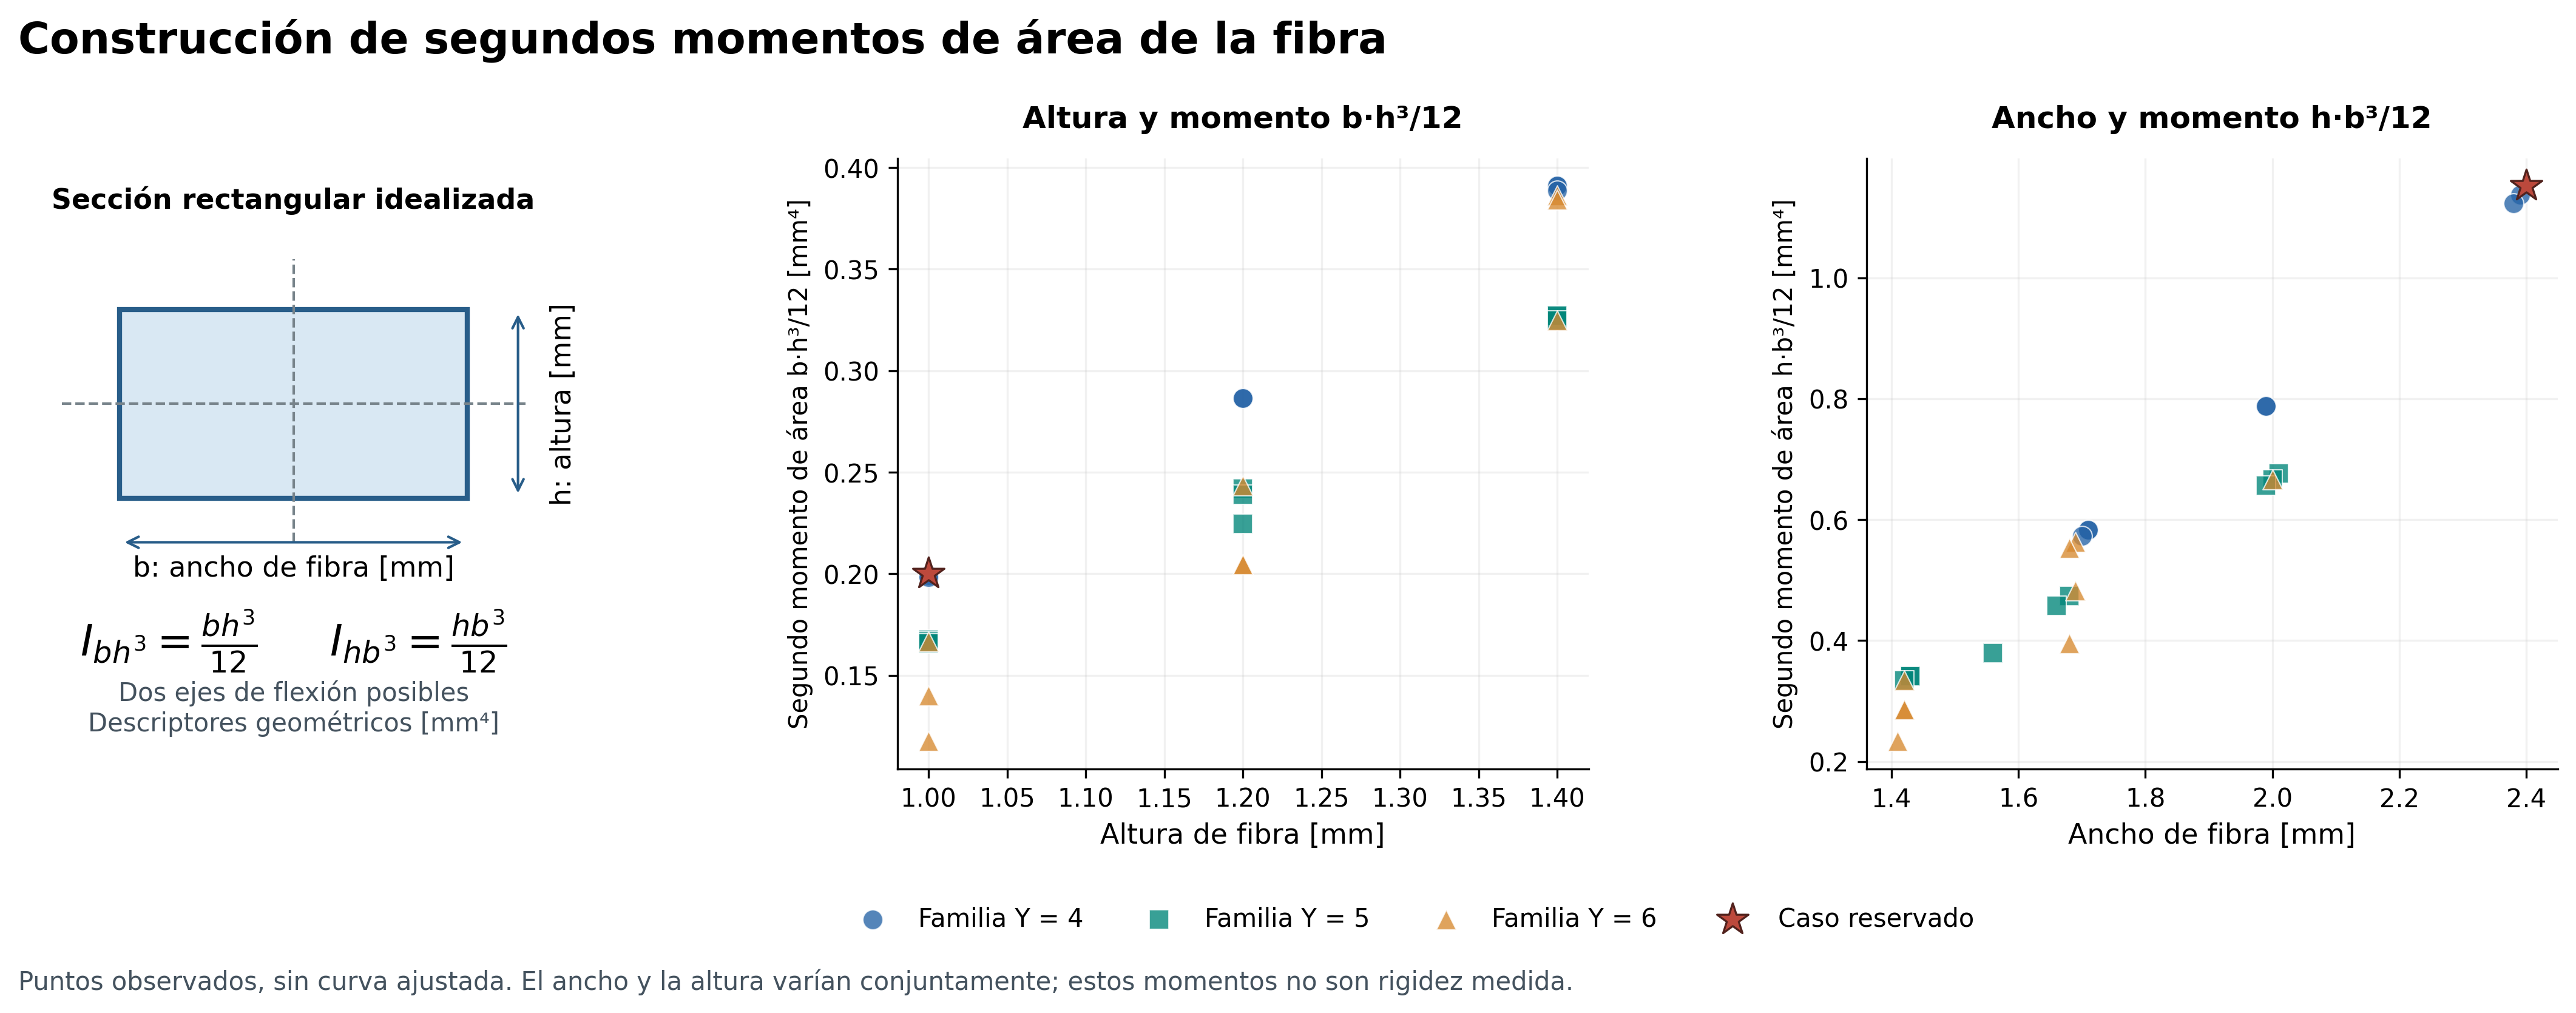

Los dos momentos representan orientaciones distintas de una sección rectangular; no son rigidez EI medida. Se prueban juntos: ΔMAE de variante 1 frente a la base = -0.4119 N.

[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_formulas_por_caso.csv).

In [7]:
mostrar_figura('FE08_momentos')
display(Markdown('[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_formulas_por_caso.csv).'))

### Tratamiento 2. Razón de volúmenes antes y después del logaritmo

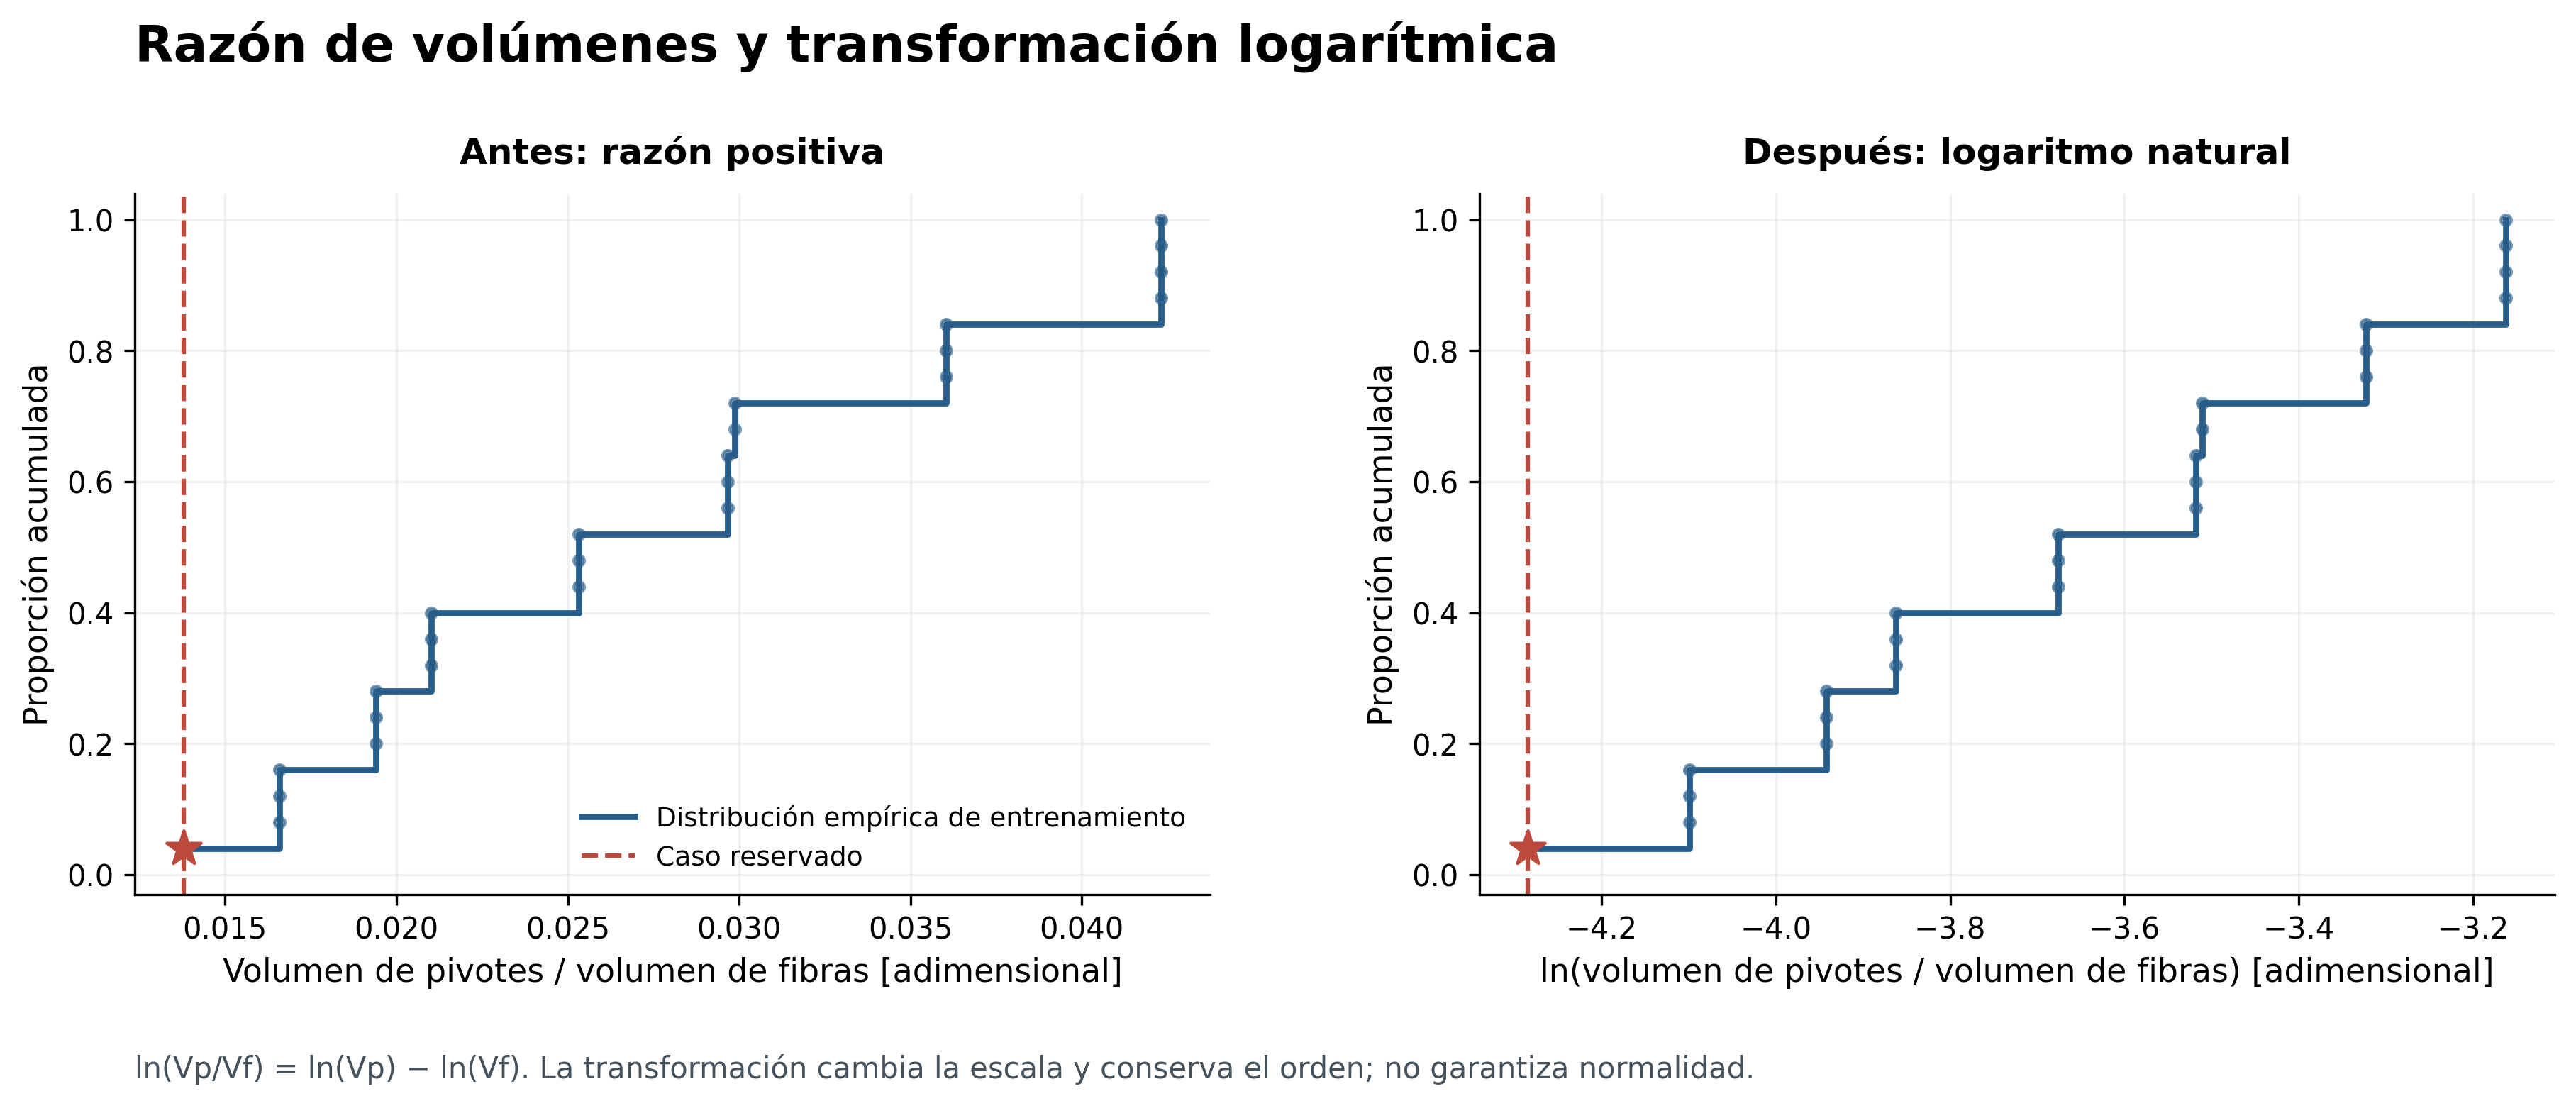

El logaritmo conserva el orden y modifica las distancias entre valores. Un resultado negativo indica menos volumen de pivotes que de fibras. Añadir esta característica cambia el MAE en +0.0792 N frente a la variante 1.

[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_razon_log.csv).

In [8]:
mostrar_figura('FE09_razon_log')
display(Markdown('[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_razon_log.csv).'))

### Tratamiento 3. Evidencia geométrica para estudiar redundancia

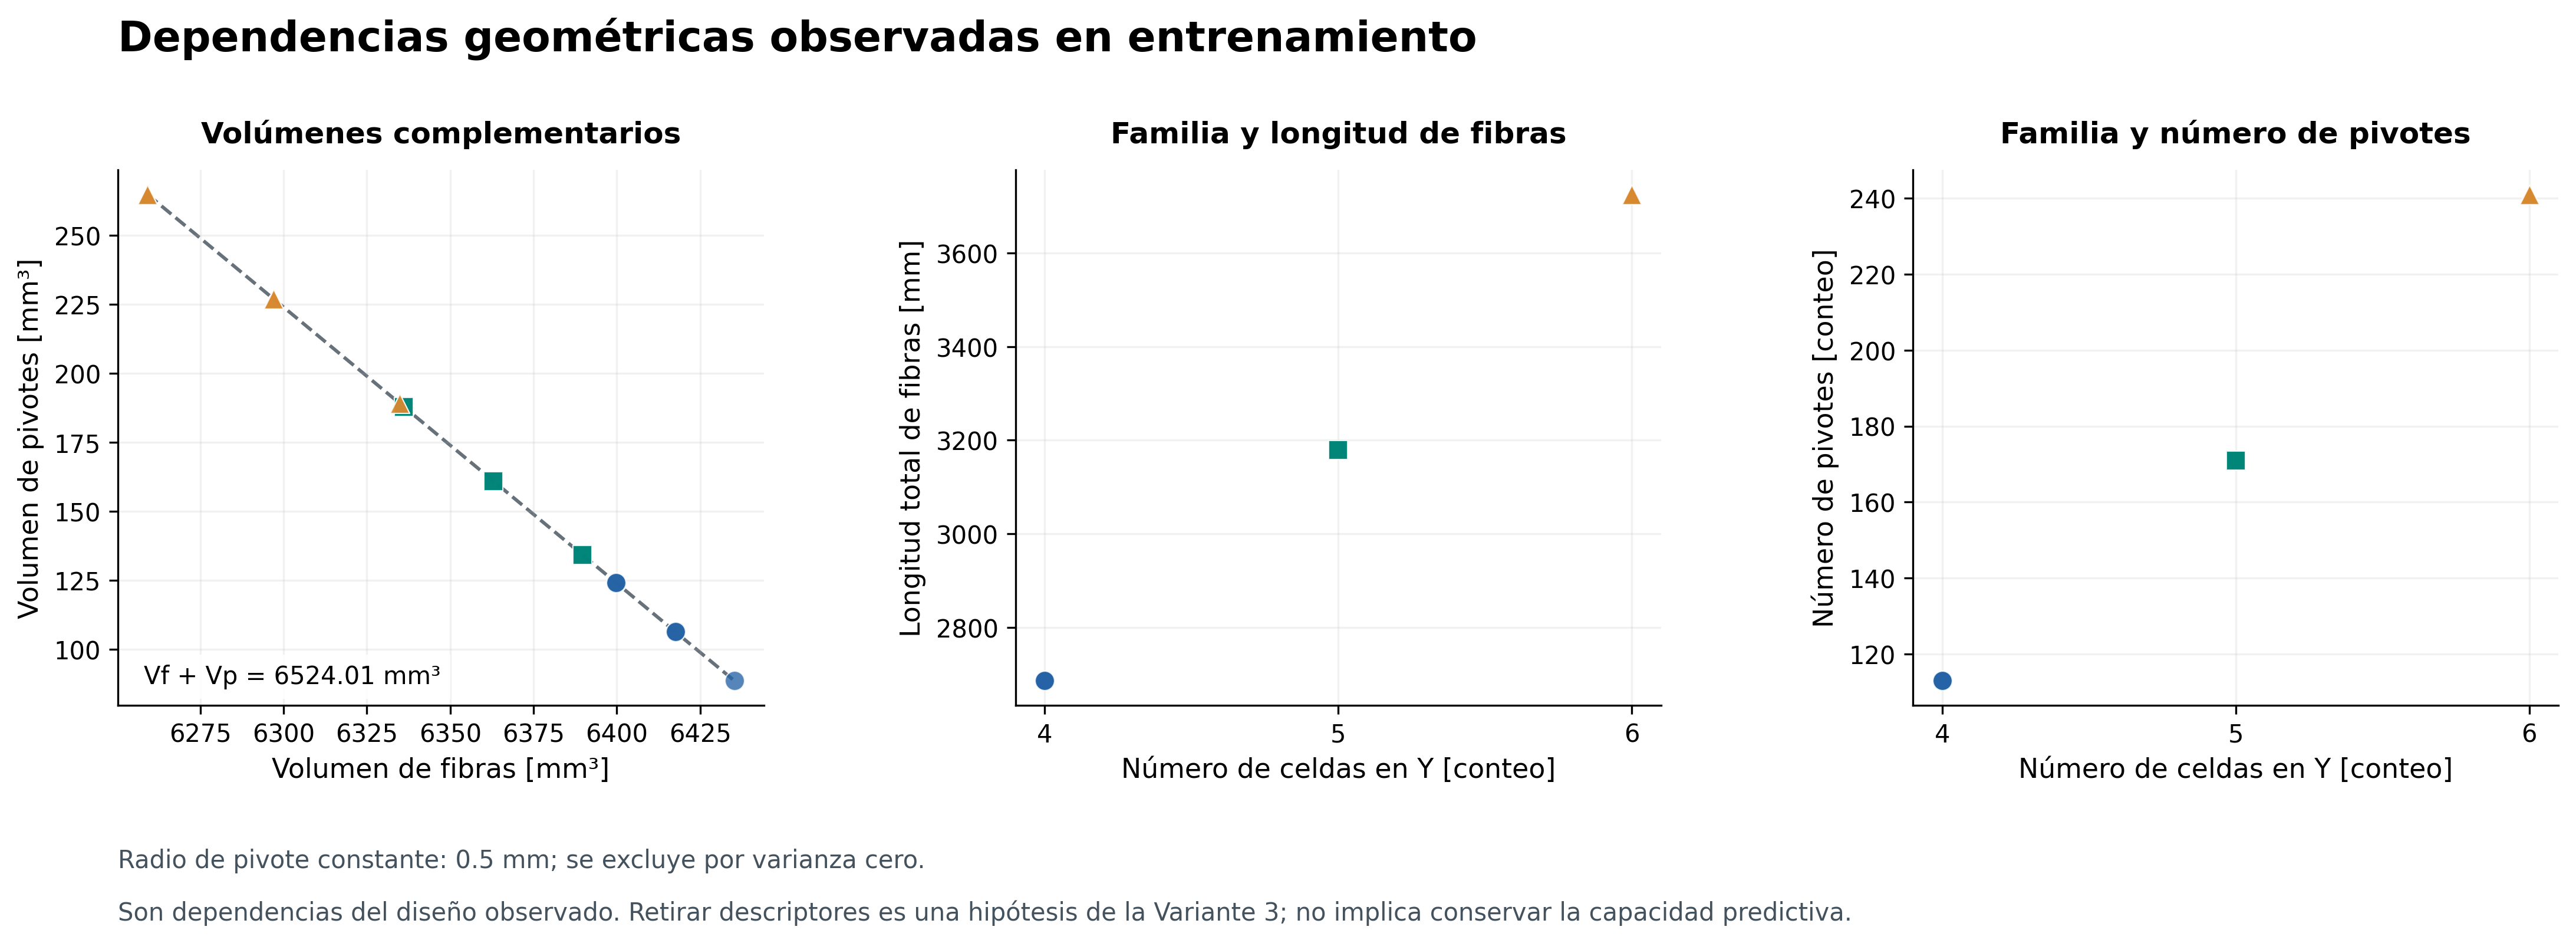

La dependencia se observa en este diseño. El radio constante se filtra en entrenamiento; retirar además el bloque de tres descriptores cambia el MAE en +4.1211 N frente a la variante 2. La redundancia no basta para recomendar su eliminación.

[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_decisiones.csv).

In [9]:
mostrar_figura('FE10_redundancia')
display(Markdown('[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_decisiones.csv).'))

### Tratamiento 4. Escalas originales y estandarización

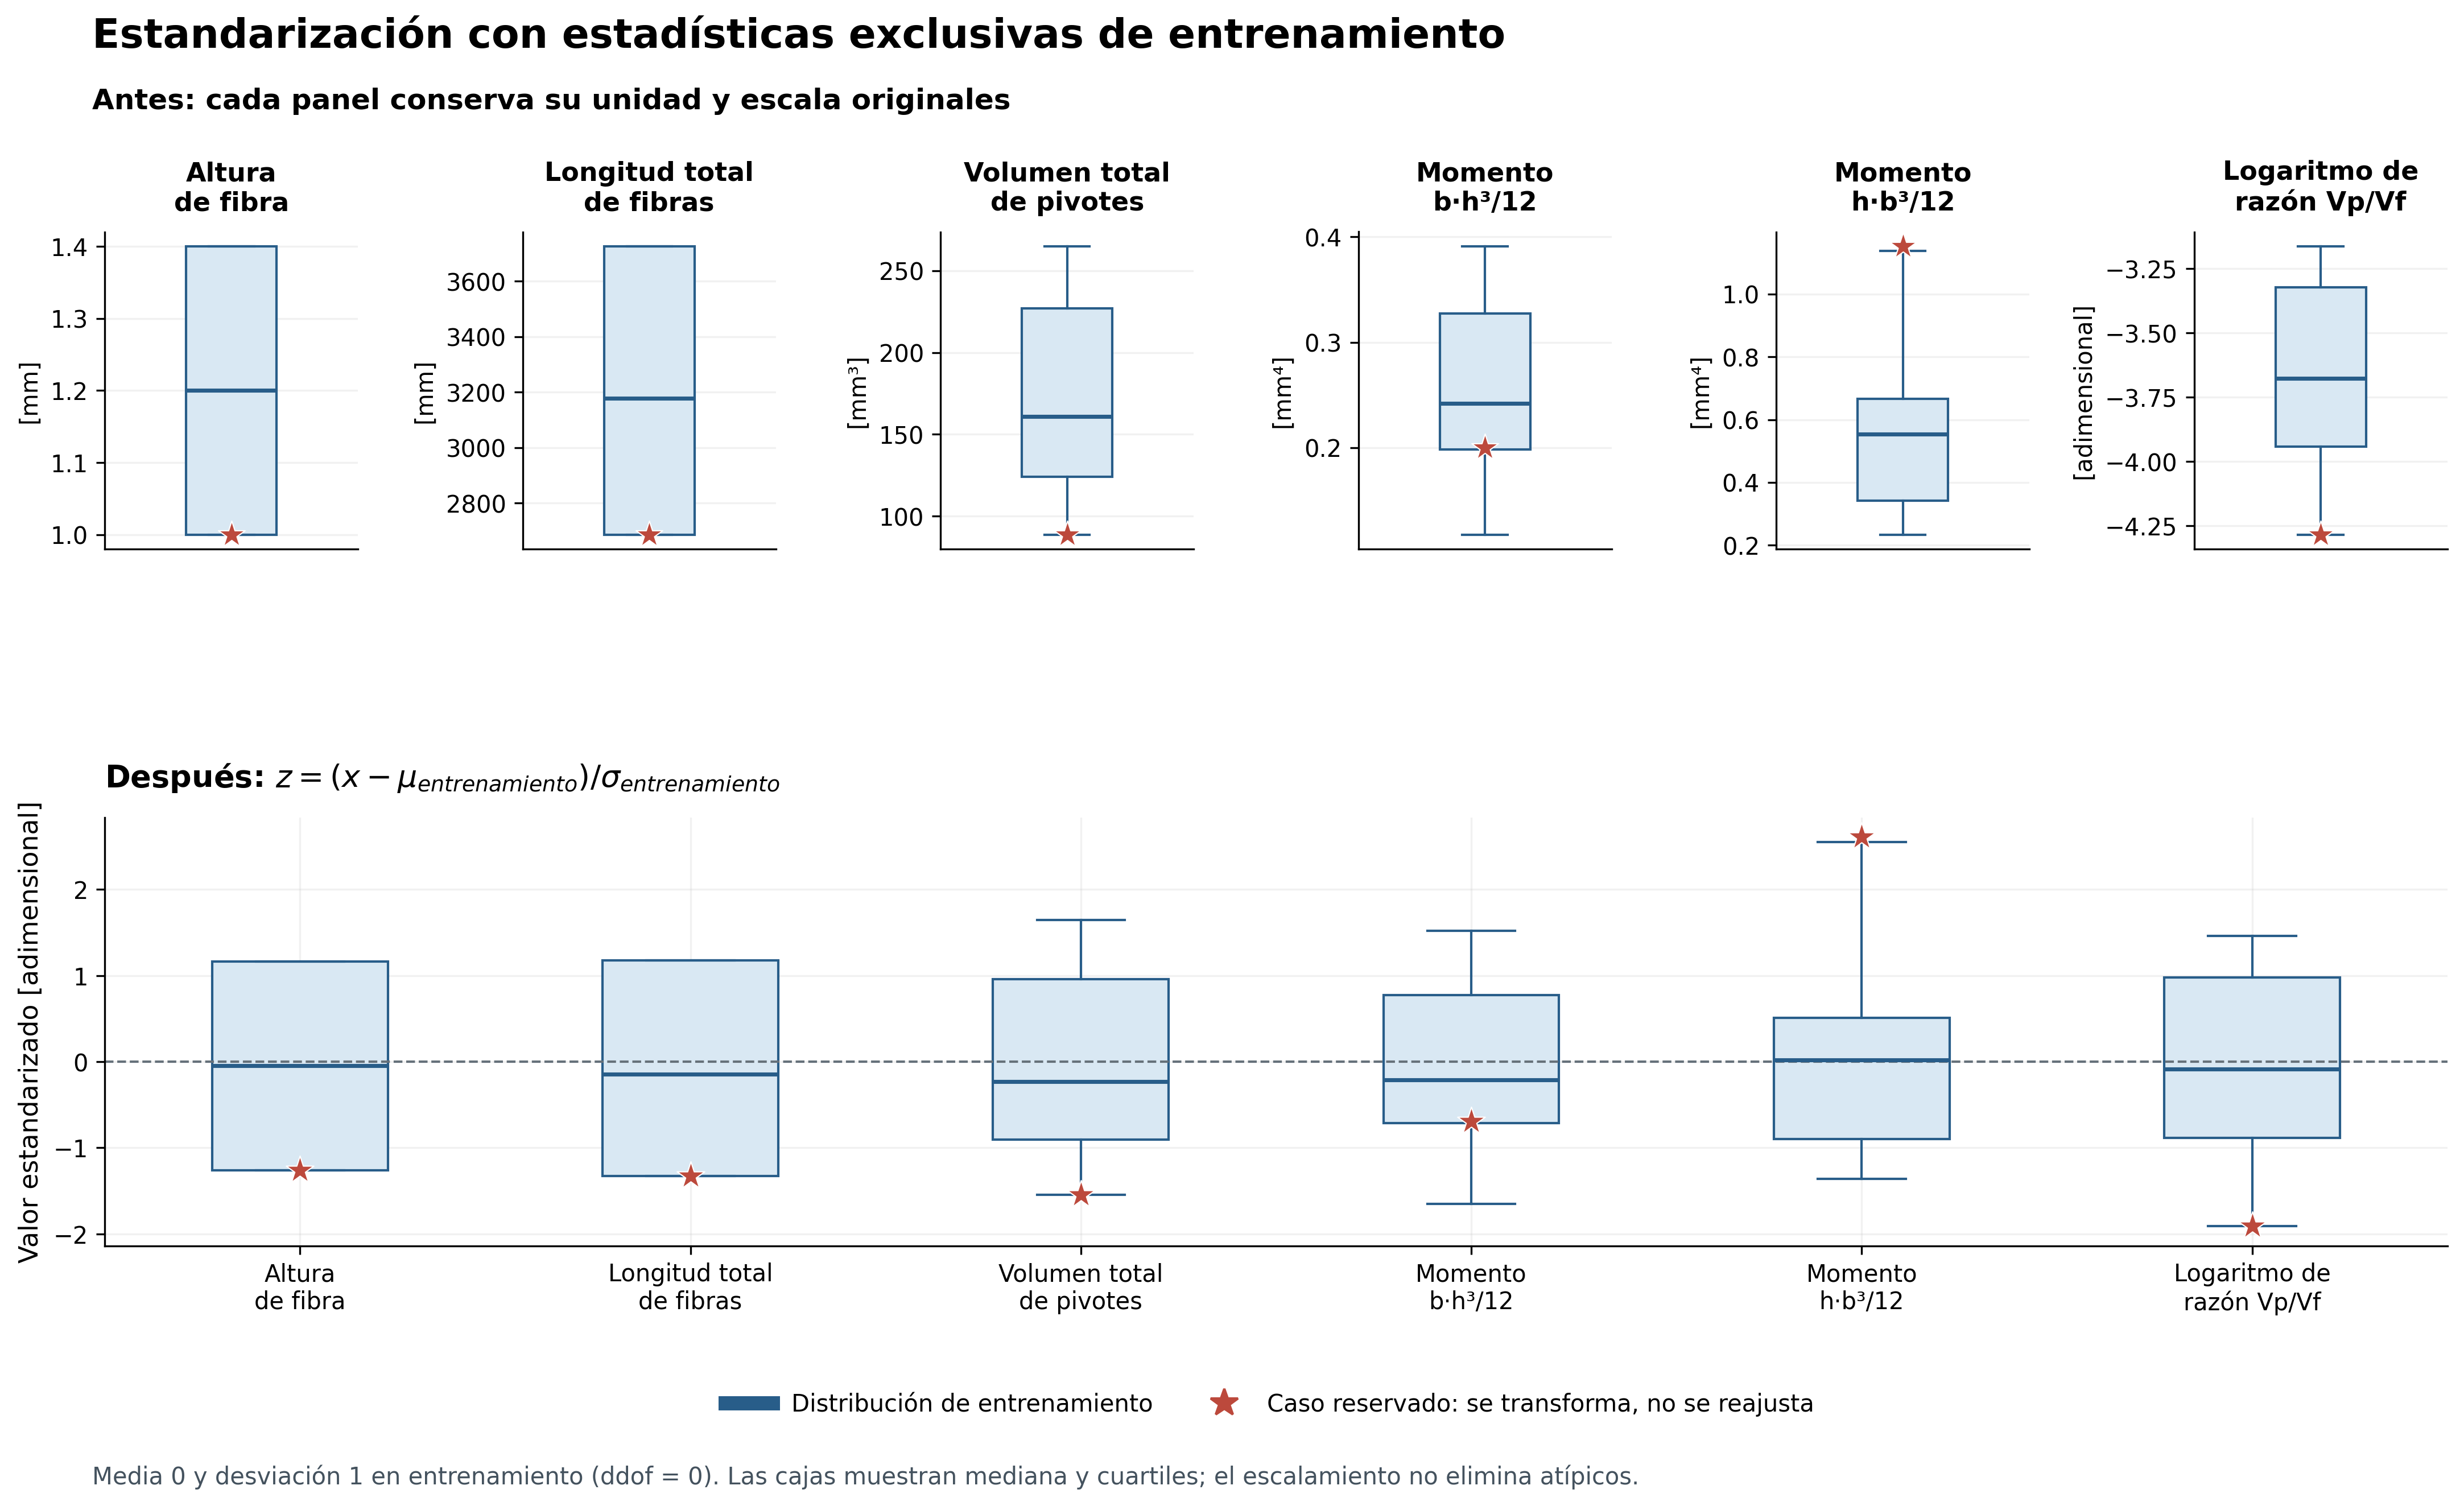

Las medias y escalas proceden únicamente del entrenamiento. El caso reservado reutiliza esas estadísticas y no tiene por qué quedar centrado en cero. La estandarización cambia la escala numérica, no la geometría física.

[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_escalamiento.csv).

In [10]:
mostrar_figura('FE11_escalamiento')
display(Markdown('[Evidencia del tratamiento](../reports/feature_engineering/tables/tratamiento_escalamiento.csv).'))

## 4.4 Conjunto de características y redundancia

El mapa muestra las variables añadidas y retiradas en cada variante. La retirada de constantes se aprende en cada entrenamiento; la reducción de la variante 3 está fijada por hipótesis. El rango describe dependencia lineal, no precisión predictiva.

### Figura 1. Variables que llegan a cada experimento

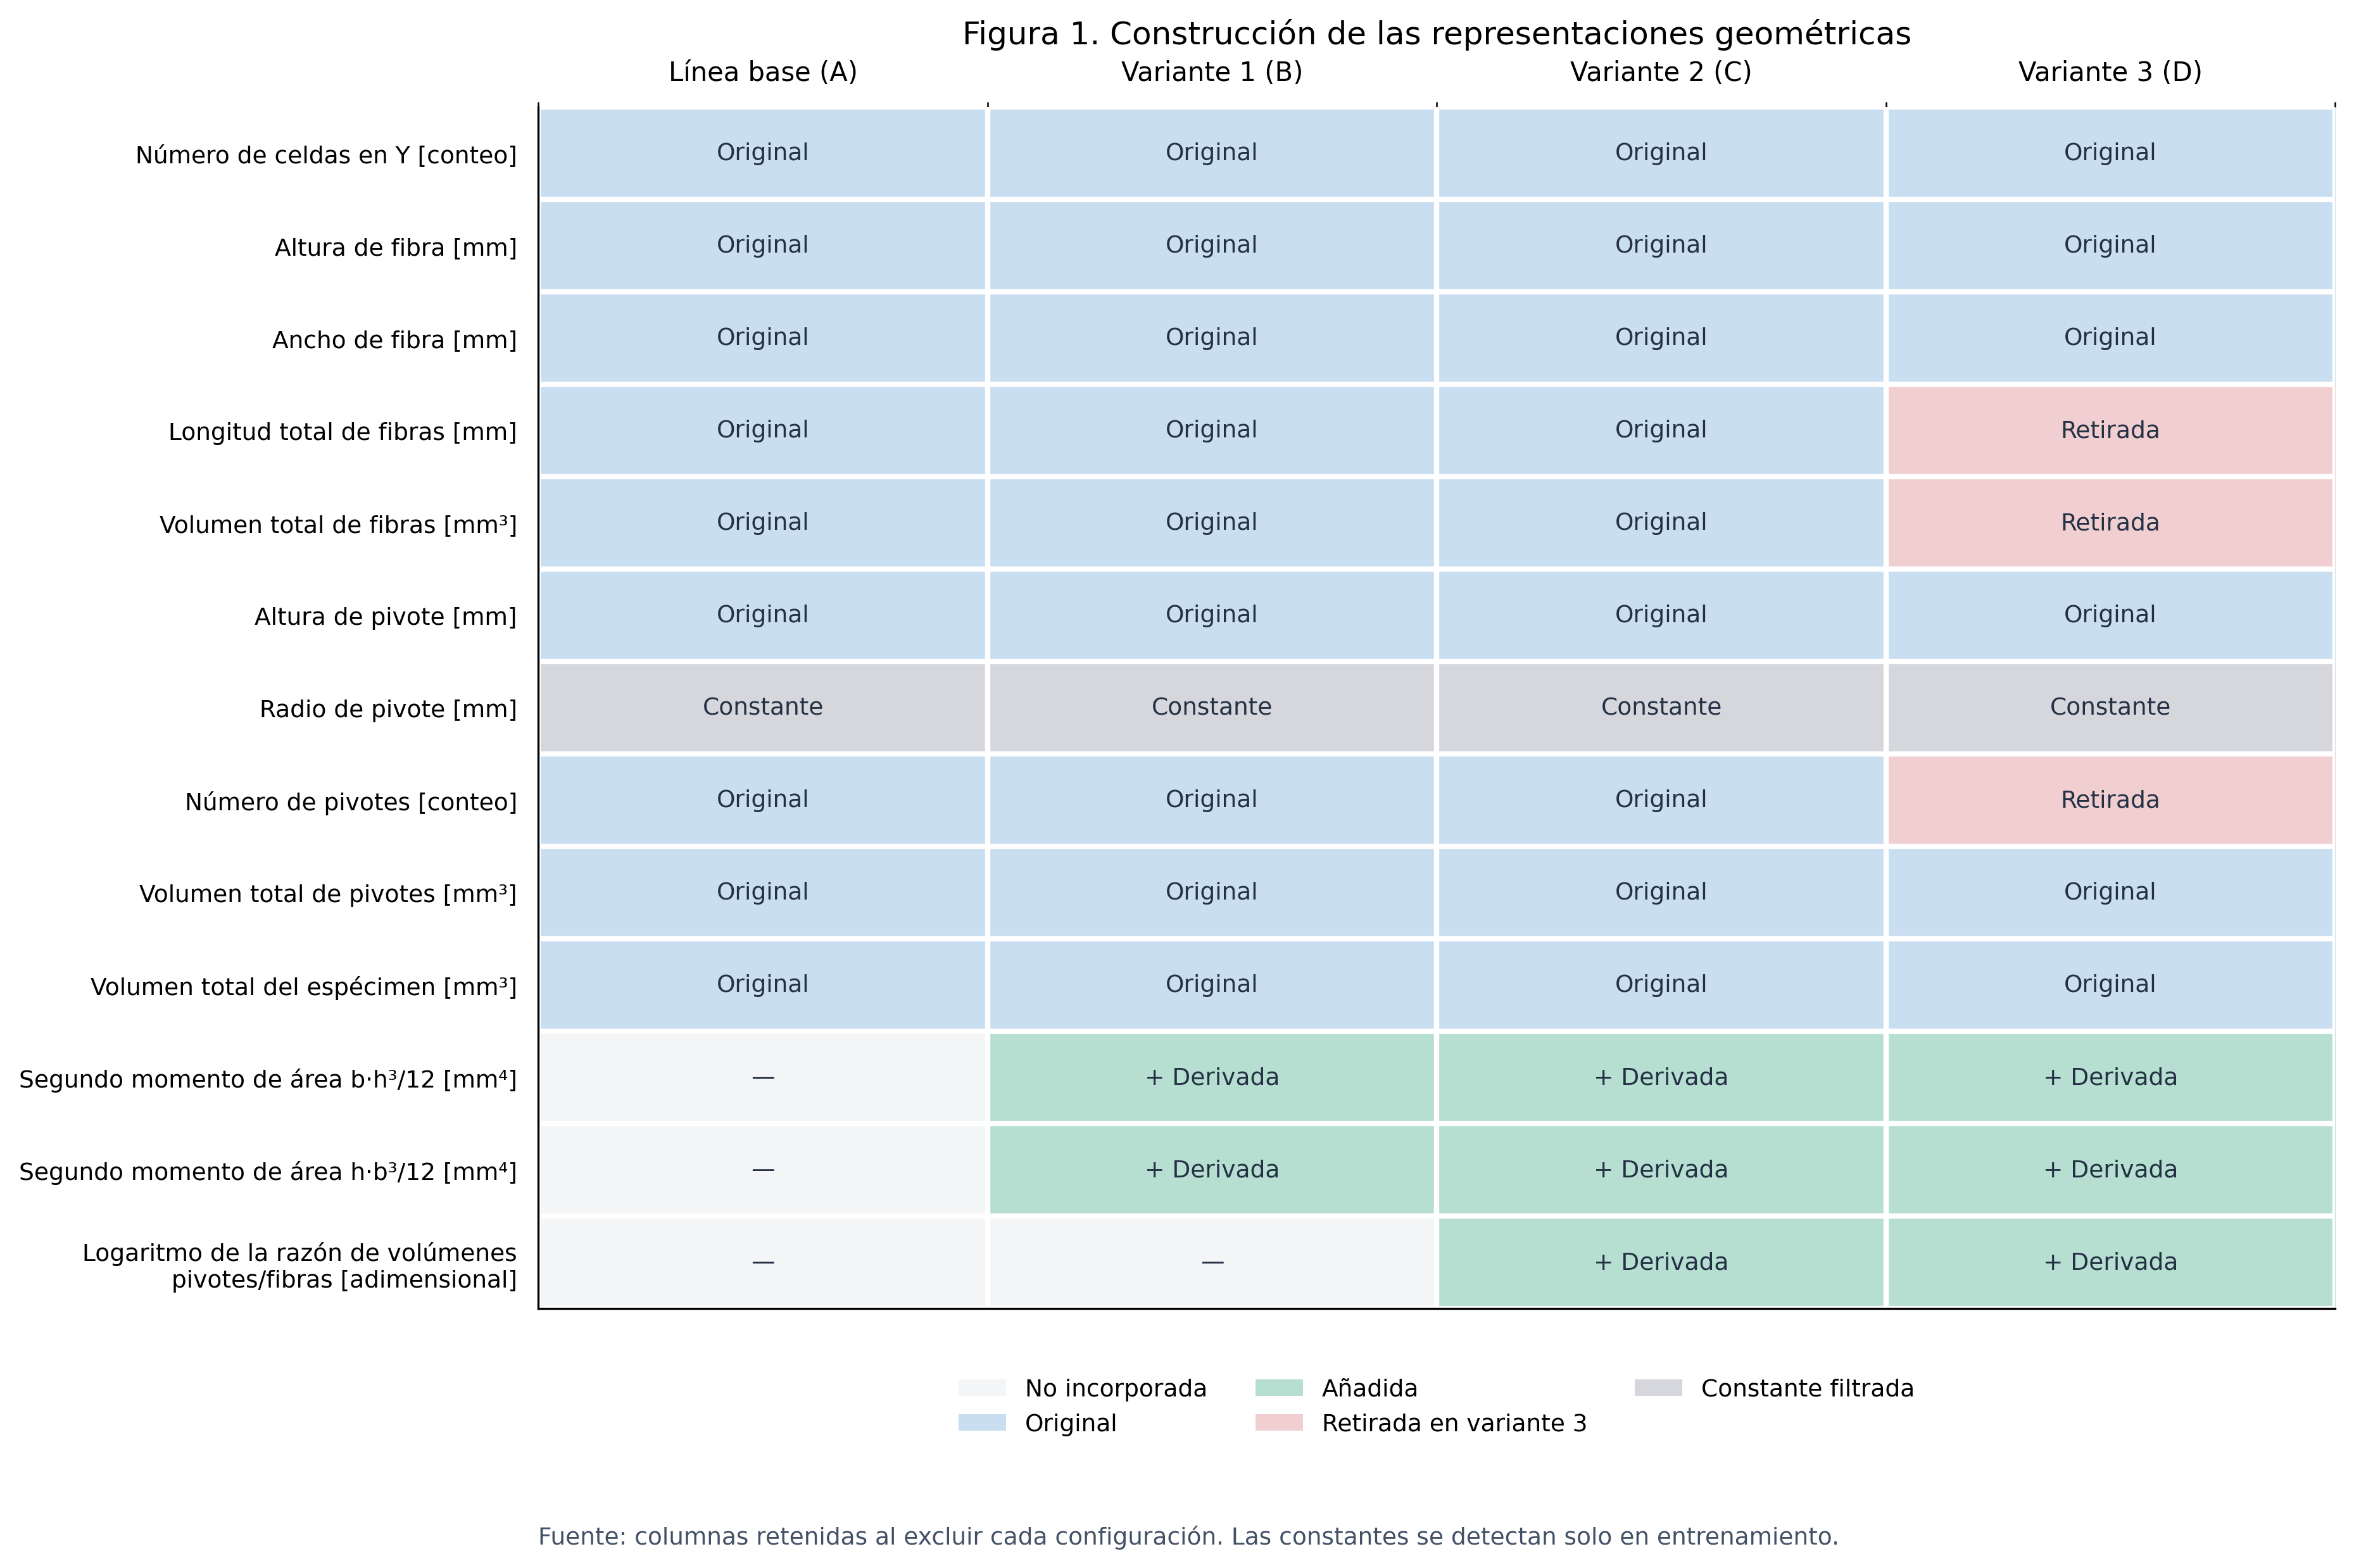

El filtro de varianza retira el radio constante dentro de cada entrenamiento. D retira además tres columnas por hipótesis geométrica; el volumen de fibras sigue interviniendo en la razón logarítmica. Añadir columnas no añade mediciones.

In [11]:
mostrar_figura('FE06_representaciones')

### Figura 2. Dimensión y rango de la representación

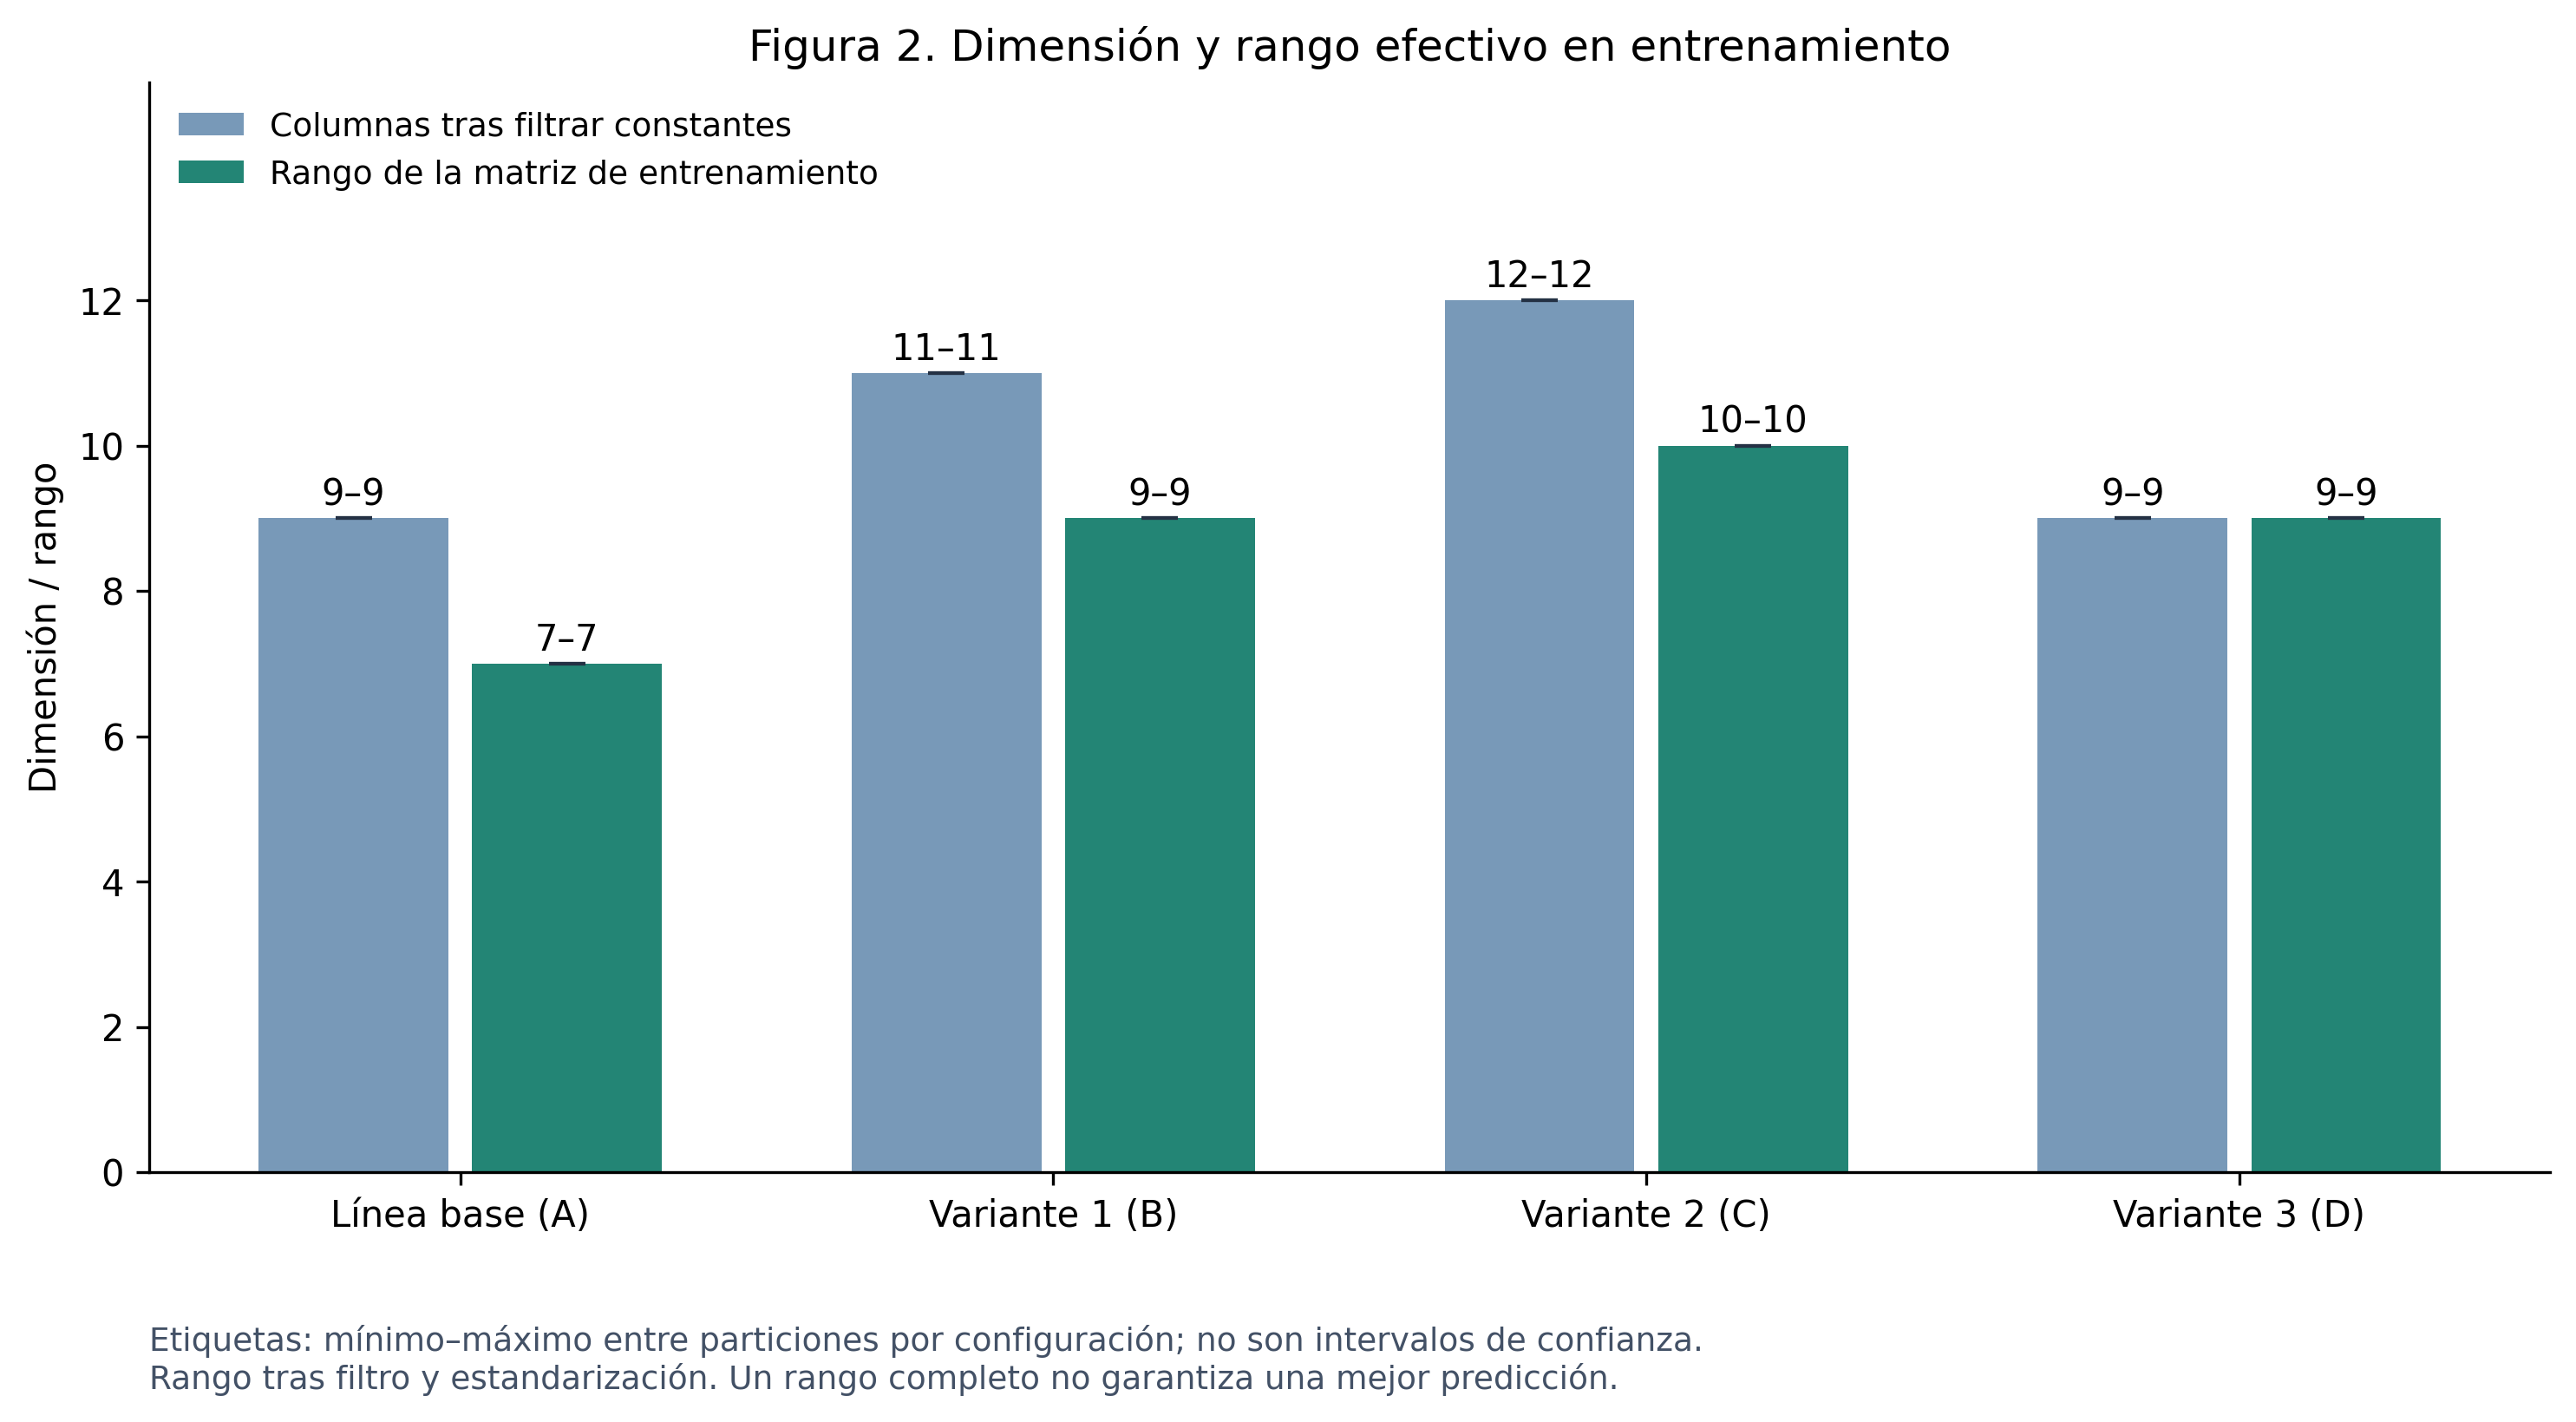

El rango se calcula después de transformar y estandarizar cada entrenamiento. Un rango menor que el número de columnas indica dependencia lineal en ese diseño. Las fórmulas no lineales pueden aumentar el rango sin aportar nuevas observaciones ni garantizar menor error.

In [12]:
mostrar_figura('FE07_rango')

## 4.5 Validación cruzada por grupos y control de fuga

Se utiliza **LeaveOneGroupOut**: se reserva una configuración completa (celdas en Y, altura de fibra y altura de pivote), se entrena con las restantes y se repite hasta evaluar todos los grupos. La comprobación adicional reserva una familia Y completa. No se ha utilizado un holdout externo, una partición temporal ni estratificación.

Primero se comprueban todas las particiones; después se reconstruye la predicción del caso de 4.2. Su respuesta reservada se consulta únicamente para evaluar el error.

In [13]:
from src.verificar_fe import auditar_preprocesamiento
particiones_completas = json.loads((SALIDA / 'particiones.json').read_text(encoding='utf-8'))
auditorias_completas = json.loads((SALIDA / 'auditoria_transformaciones.json').read_text(encoding='utf-8'))
estadisticas = auditar_preprocesamiento(datos_fuente, auditorias_completas)
indice_fuente = datos_fuente.set_index('Case_n')
for division in particiones_completas:
    casos_entrenamiento, casos_validacion = division['train_cases'], division['test_cases']
    assert set(casos_entrenamiento).isdisjoint(casos_validacion)
    agrupacion = (grupos_nominales(indice_fuente, configuracion['group_columns'])
                  if division['protocolo'] == 'configuracion' else indice_fuente['n_cells_Y'])
    assert set(agrupacion.loc[casos_entrenamiento]).isdisjoint(agrupacion.loc[casos_validacion])
    for experimento in ['Dummy', *configuracion['experiments']]:
        filas = predicciones.loc[(predicciones.protocolo == division['protocolo'])
                                  & (predicciones.fold == division['fold'])
                                  & (predicciones.experimento == experimento)]
        assert set(filas.Case_n) == set(casos_validacion)
for _, filas in predicciones.groupby(['protocolo', 'experimento']):
    assert not filas.Case_n.duplicated().any()
    assert set(filas.Case_n) == set(datos_fuente.Case_n)

comprobaciones = {
    'Objetivo e identificador excluidos de entradas': objetivo not in entradas and 'identificador_caso' not in entradas,
    'Casos y grupos separados; mismas particiones entre variantes': True,
    'Una predicción fuera de muestra por caso y experimento': True,
    'Medianas calculadas solo con entrenamiento': estadisticas.medianas_correctas.all(),
    'Variables retenidas según varianza de entrenamiento': estadisticas.variables_correctas.all(),
    'Medias y escalas calculadas solo con entrenamiento': estadisticas.medias_correctas.all() and estadisticas.escalas_correctas.all(),
}
assert all(comprobaciones.values())
mostrar_tabla(pd.DataFrame({'Control ejecutado': list(comprobaciones),
                           'Resultado': ['Correcto' if v else 'Revisar' for v in comprobaciones.values()]}))
display(Markdown('**Sin fuga de información detectada en estos controles de entradas, particiones y preprocesamiento.** El EDA previo utilizó todo el conjunto: permanece el posible sesgo de selección de hipótesis; no se afirma una validación externa.'))

Control ejecutado,Resultado
Objetivo e identificador excluidos de entradas,Correcto
Casos y grupos separados; mismas particiones entre variantes,Correcto
Una predicción fuera de muestra por caso y experimento,Correcto
Medianas calculadas solo con entrenamiento,Correcto
Variables retenidas según varianza de entrenamiento,Correcto
Medias y escalas calculadas solo con entrenamiento,Correcto


**Sin fuga de información detectada en estos controles de entradas, particiones y preprocesamiento.** El EDA previo utilizó todo el conjunto: permanece el posible sesgo de selección de hipótesis; no se afirma una validación externa.

In [14]:
particiones = json.loads((SALIDA / 'particiones.json').read_text(encoding='utf-8'))
auditorias = json.loads((SALIDA / 'auditoria_transformaciones.json').read_text(encoding='utf-8'))
particion = next(p for p in particiones
                 if p['protocolo'] == 'configuracion' and caso in p['test_cases'])
registro = next(a for a in auditorias if a['protocolo'] == 'configuracion'
                and a['experimento'] == 'B' and a['fold'] == particion['fold'])
por_caso = datos.set_index('identificador_caso')
entrenamiento = por_caso.loc[particion['train_cases']]
validacion = por_caso.loc[particion['test_cases']]
grupos_entrenamiento = set(grupos_nominales(a_fuente(entrenamiento), configuracion['group_columns']))
grupos_validacion = set(grupos_nominales(a_fuente(validacion), configuracion['group_columns']))
assert grupos_entrenamiento.isdisjoint(grupos_validacion)

pipeline = crear_pipeline('B', alpha=configuracion['model']['alpha'])
with threadpool_limits(limits=1):
    pipeline.fit(a_fuente(entrenamiento[columnas_entrada]), entrenamiento[objetivo])
    estimacion = pipeline.predict(a_fuente(validacion[columnas_entrada]))
np.testing.assert_allclose(pipeline.named_steps['imputer'].statistics_, registro['imputer_median'])
np.testing.assert_allclose(pipeline.named_steps['scale'].mean_, registro['scaler_mean'])
np.testing.assert_allclose(pipeline.named_steps['scale'].scale_, registro['scaler_scale'])
guardadas = predicciones.query("protocolo == 'configuracion' and experimento == 'B'").set_index('Case_n')
np.testing.assert_allclose(estimacion, guardadas.loc[validacion.index, 'predicho_N'], atol=1e-10)

mostrar_tabla(pd.DataFrame([
    ['Partición reconstruida', str(particion['fold'])],
    ['Grupo reservado (celdas Y | altura fibra | altura pivote)', particion['grupo_excluido']],
    ['Casos reservados', ', '.join(map(str, particion['test_cases']))],
    ['Grupos compartidos entre entrenamiento y validación', str(sorted(grupos_entrenamiento & grupos_validacion))],
    ['Estadísticas y predicción', 'Coinciden con la ejecución guardada'],
], columns=['Comprobación', 'Resultado']))

Comprobación,Resultado
Partición reconstruida,6
Grupo reservado (celdas Y | altura fibra | altura pivote),4|1|1
Casos reservados,1
Grupos compartidos entre entrenamiento y validación,[]
Estadísticas y predicción,Coinciden con la ejecución guardada


In [15]:
nombres = [NOMBRES_VARIABLES[n] for n in nombres_modelo(pipeline)]
previas = pipeline[:3].transform(a_fuente(validacion[columnas_entrada])).rename(columns=NOMBRES_VARIABLES)
estandarizadas = pd.DataFrame(pipeline[:-1].transform(a_fuente(validacion[columnas_entrada])),
                              index=validacion.index, columns=nombres)
medias = pd.Series(pipeline.named_steps['scale'].mean_, index=nombres)
escalas = pd.Series(pipeline.named_steps['scale'].scale_, index=nombres)
medianas = pd.Series(pipeline.named_steps['imputer'].statistics_, index=columnas_entrada)
seleccionadas = ['numero_celdas_y', 'altura_fibra_mm', 'ancho_fibra_mm', *columnas_derivadas[:2]]
vista = pd.DataFrame({
    'Variable': seleccionadas,
    'Valor antes de escalar': previas.loc[caso, seleccionadas].to_numpy(),
    'Mediana de entrenamiento': medianas.reindex(seleccionadas).to_numpy(),
    'Media de entrenamiento': medias[seleccionadas].to_numpy(),
    'Escala de entrenamiento': escalas[seleccionadas].to_numpy(),
    'Valor estandarizado': estandarizadas.loc[caso, seleccionadas].to_numpy(),
})
np.testing.assert_allclose(estandarizadas[seleccionadas],
                           (previas[seleccionadas] - medias[seleccionadas]) / escalas[seleccionadas])
mostrar_tabla(vista)
display(Markdown('Los momentos se calculan después de imputar sus ingredientes; por eso no tienen mediana de imputación propia. La estandarización utiliza exclusivamente estadísticas del entrenamiento.'))

Variable,Valor antes de escalar,Mediana de entrenamiento,Media de entrenamiento,Escala de entrenamiento,Valor estandarizado
Número de celdas en Y,4.0000,5.0000,5.0800,0.7960,-1.3568
Altura de fibra,1.0000,1.2000,1.2080,0.1647,-1.2627
Ancho de fibra,2.4000,1.6900,1.7384,0.2826,2.3413
Segundo momento de área b·h³/12,0.2000,—,0.2599,0.0864,-0.6934
Segundo momento de área h·b³/12,1.1520,—,0.5482,0.2312,2.6112


Los momentos se calculan después de imputar sus ingredientes; por eso no tienen mediana de imputación propia. La estandarización utiliza exclusivamente estadísticas del entrenamiento.

In [16]:
reconstruccion = (pipeline.named_steps['model'].intercept_
                 + estandarizadas.to_numpy() @ pipeline.named_steps['model'].coef_)
np.testing.assert_allclose(estimacion, reconstruccion, atol=1e-10)
mostrar_tabla(pd.DataFrame({
    'Caso reservado': validacion.index,
    'Carga de primera falla observada [N]': validacion[objetivo].to_numpy(),
    'Predicción de variante 1 [N]': estimacion,
    'Error absoluto [N]': np.abs(validacion[objetivo].to_numpy() - estimacion),
}))
display(Markdown('La entrada es la geometría; la salida es una fuerza estimada en N. El valor observado se usa para medir el error, no para generar la predicción.'))

Caso reservado,Carga de primera falla observada [N],Predicción de variante 1 [N],Error absoluto [N]
1,47.5500,81.7562,34.2062


La entrada es la geometría; la salida es una fuerza estimada en N. El valor observado se usa para medir el error, no para generar la predicción.

## 4.6 Resultados comparables: línea base y variantes

**MAE** es el error absoluto medio principal; **RMSE**, más sensible a errores grandes; **MedAE**, el error absoluto mediano. Los tres se expresan en N. **R²** se calcula sobre las predicciones fuera de muestra reunidas (OOF), no sobre particiones individuales. Se mantiene el mismo modelo y se utiliza exactamente la misma división para todas las variantes.

In [17]:
metricas = ['MAE_N', 'RMSE_N', 'MedAE_N', 'R2_OOF']
mostrar_tabla(principal.loc[list('ABCD'), metricas + ['tiempo_s', 'n_features_max']].reset_index())
display(Markdown(
    '**Tiempo:** suma de entrenamiento y predicción de todas las particiones de esta validación; '
    'no incluye gráficos ni escritura de archivos, y depende del equipo y su carga. '
    'No es latencia de una aplicación ni costo monetario.'))
display(Markdown(f'**Control auxiliar de media:** MAE = {principal.loc["Dummy", "MAE_N"]:.4f} N. No es otra variante de características.'))

Experimento,MAE [N],RMSE [N],MedAE [N],R²,Tiempo total [s],Características
Línea base (A),13.2466,16.3457,11.9409,0.9226,0.2423,9
Variante 1 (B),12.8346,16.2029,11.7801,0.9239,0.4573,11
Variante 2 (C),12.9139,16.3271,11.8643,0.9228,0.4931,12
Variante 3 (D),17.0350,21.1361,14.9109,0.8706,0.5200,9


**Tiempo:** suma de entrenamiento y predicción de todas las particiones de esta validación; no incluye gráficos ni escritura de archivos, y depende del equipo y su carga. No es latencia de una aplicación ni costo monetario.

**Control auxiliar de media:** MAE = 56.3090 N. No es otra variante de características.

### Figura 3. Error por representación

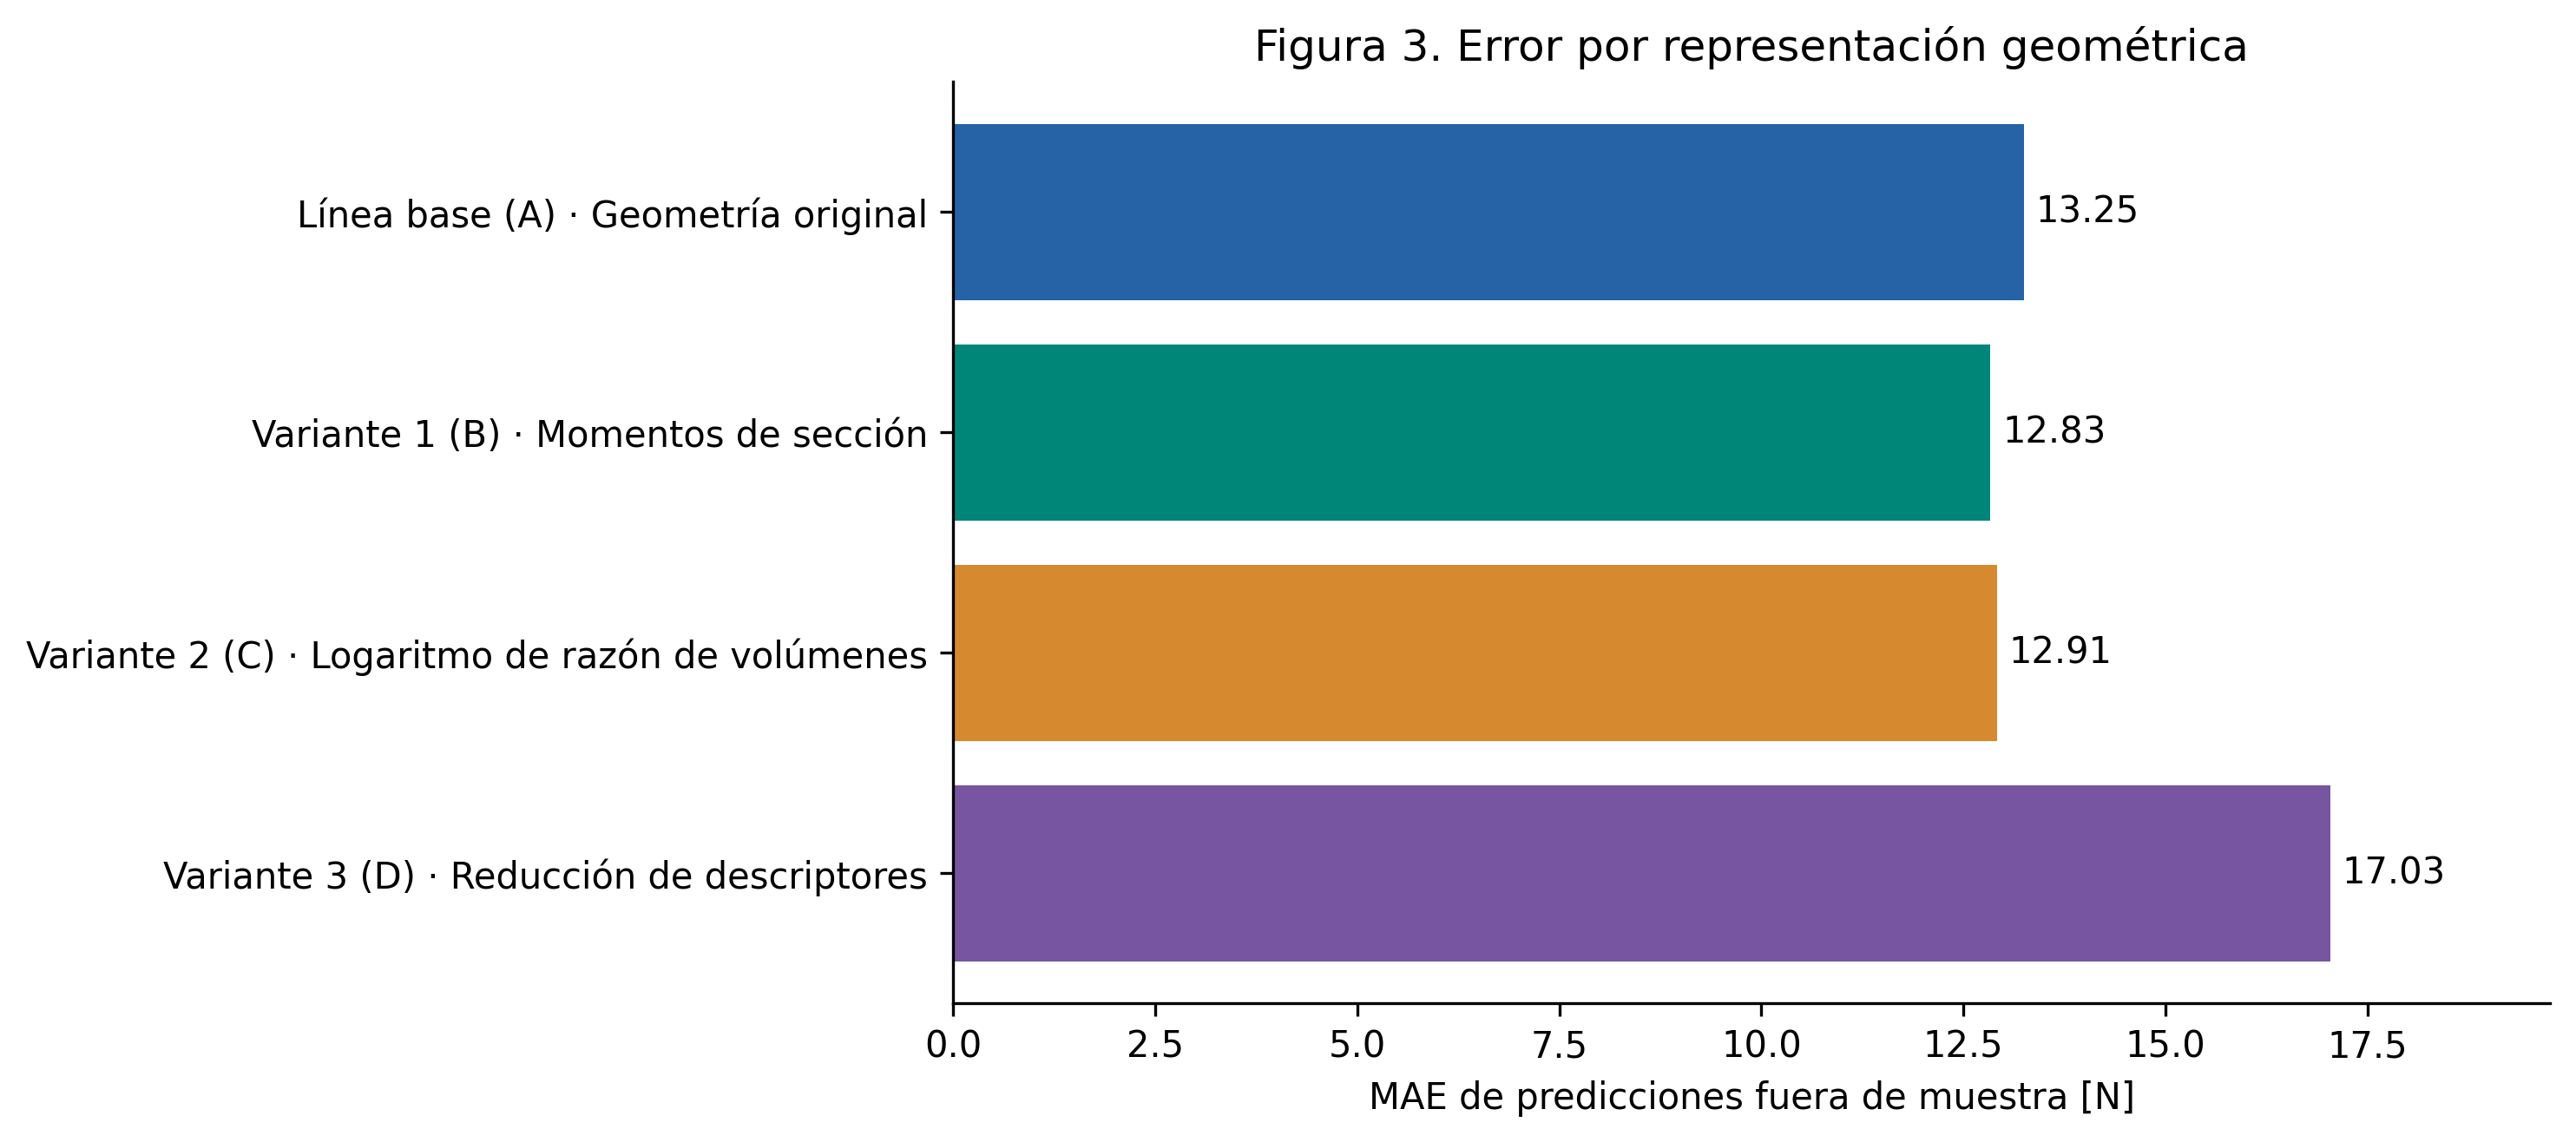

Menor MAE significa menor error medio. La dispersión entre grupos se muestra en la figura 7; estas barras no son intervalos de confianza.

In [18]:
mostrar_figura('FE01_error')

### Figura 4. Observado frente a predicho

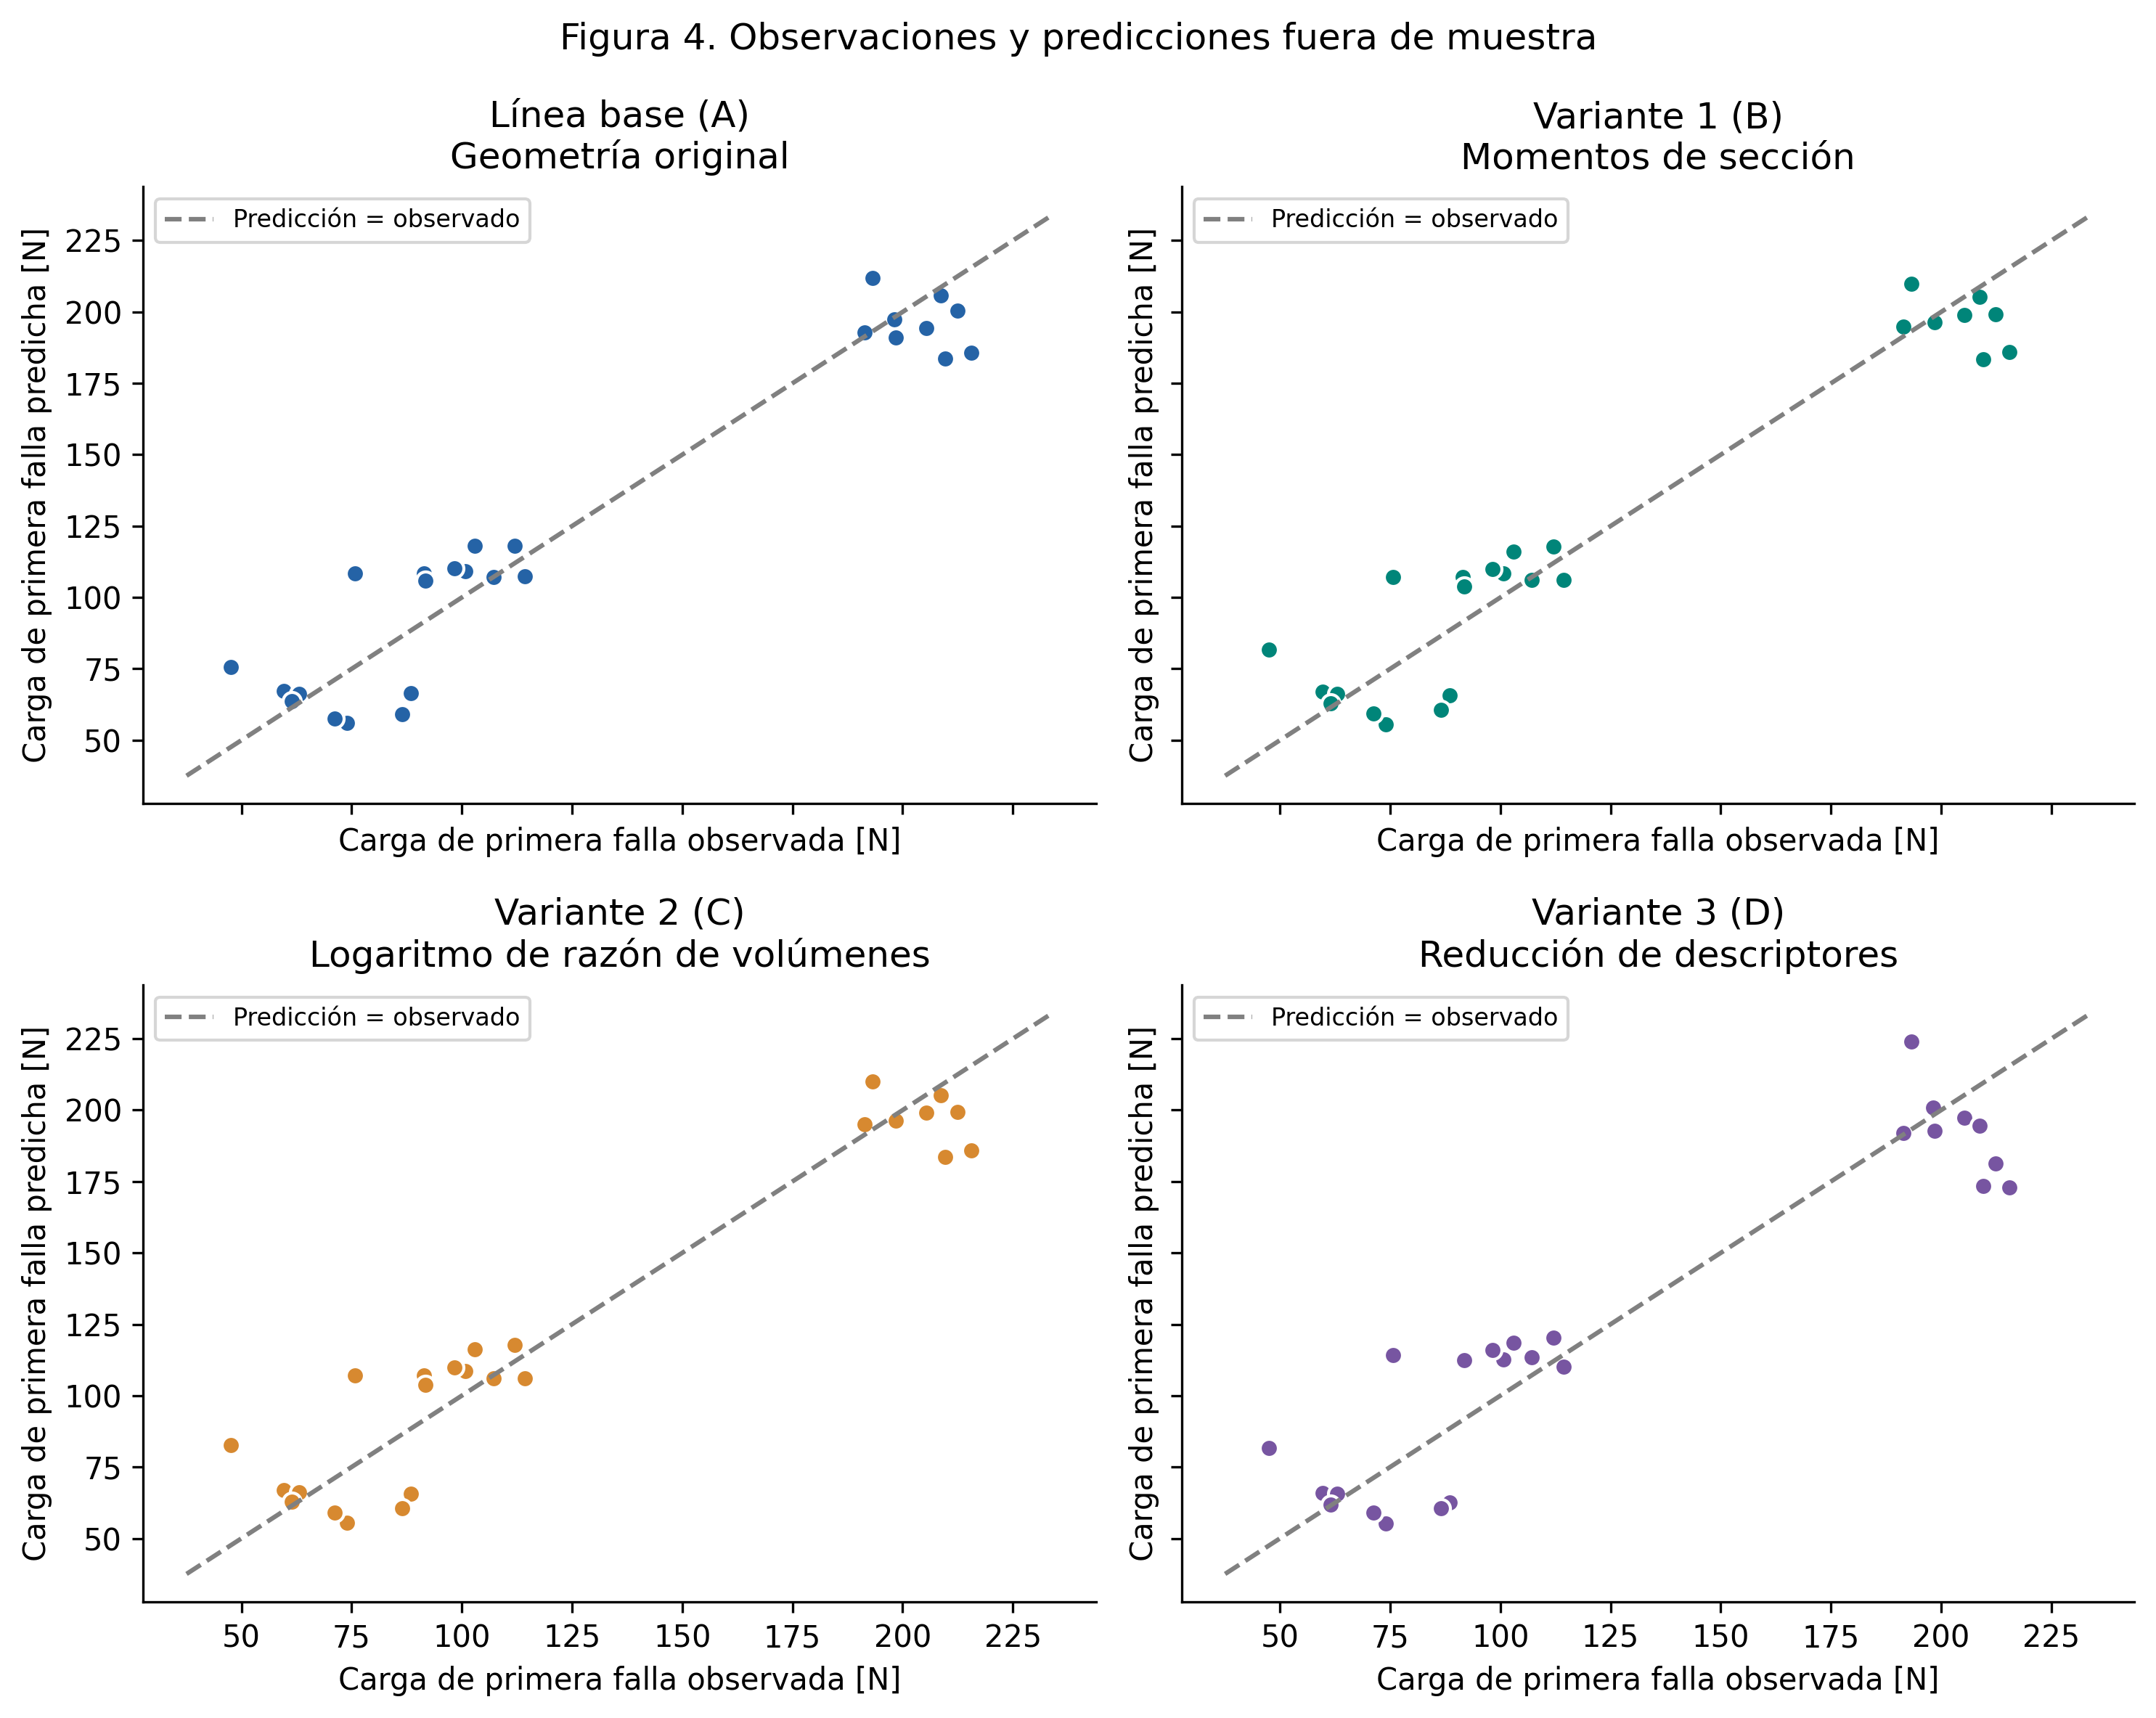

La diagonal representa coincidencia perfecta. Cada predicción procede de un modelo que no entrenó con esa configuración nominal.

In [19]:
mostrar_figura('FE02_observado_predicho')

### Figura 5. Residuales

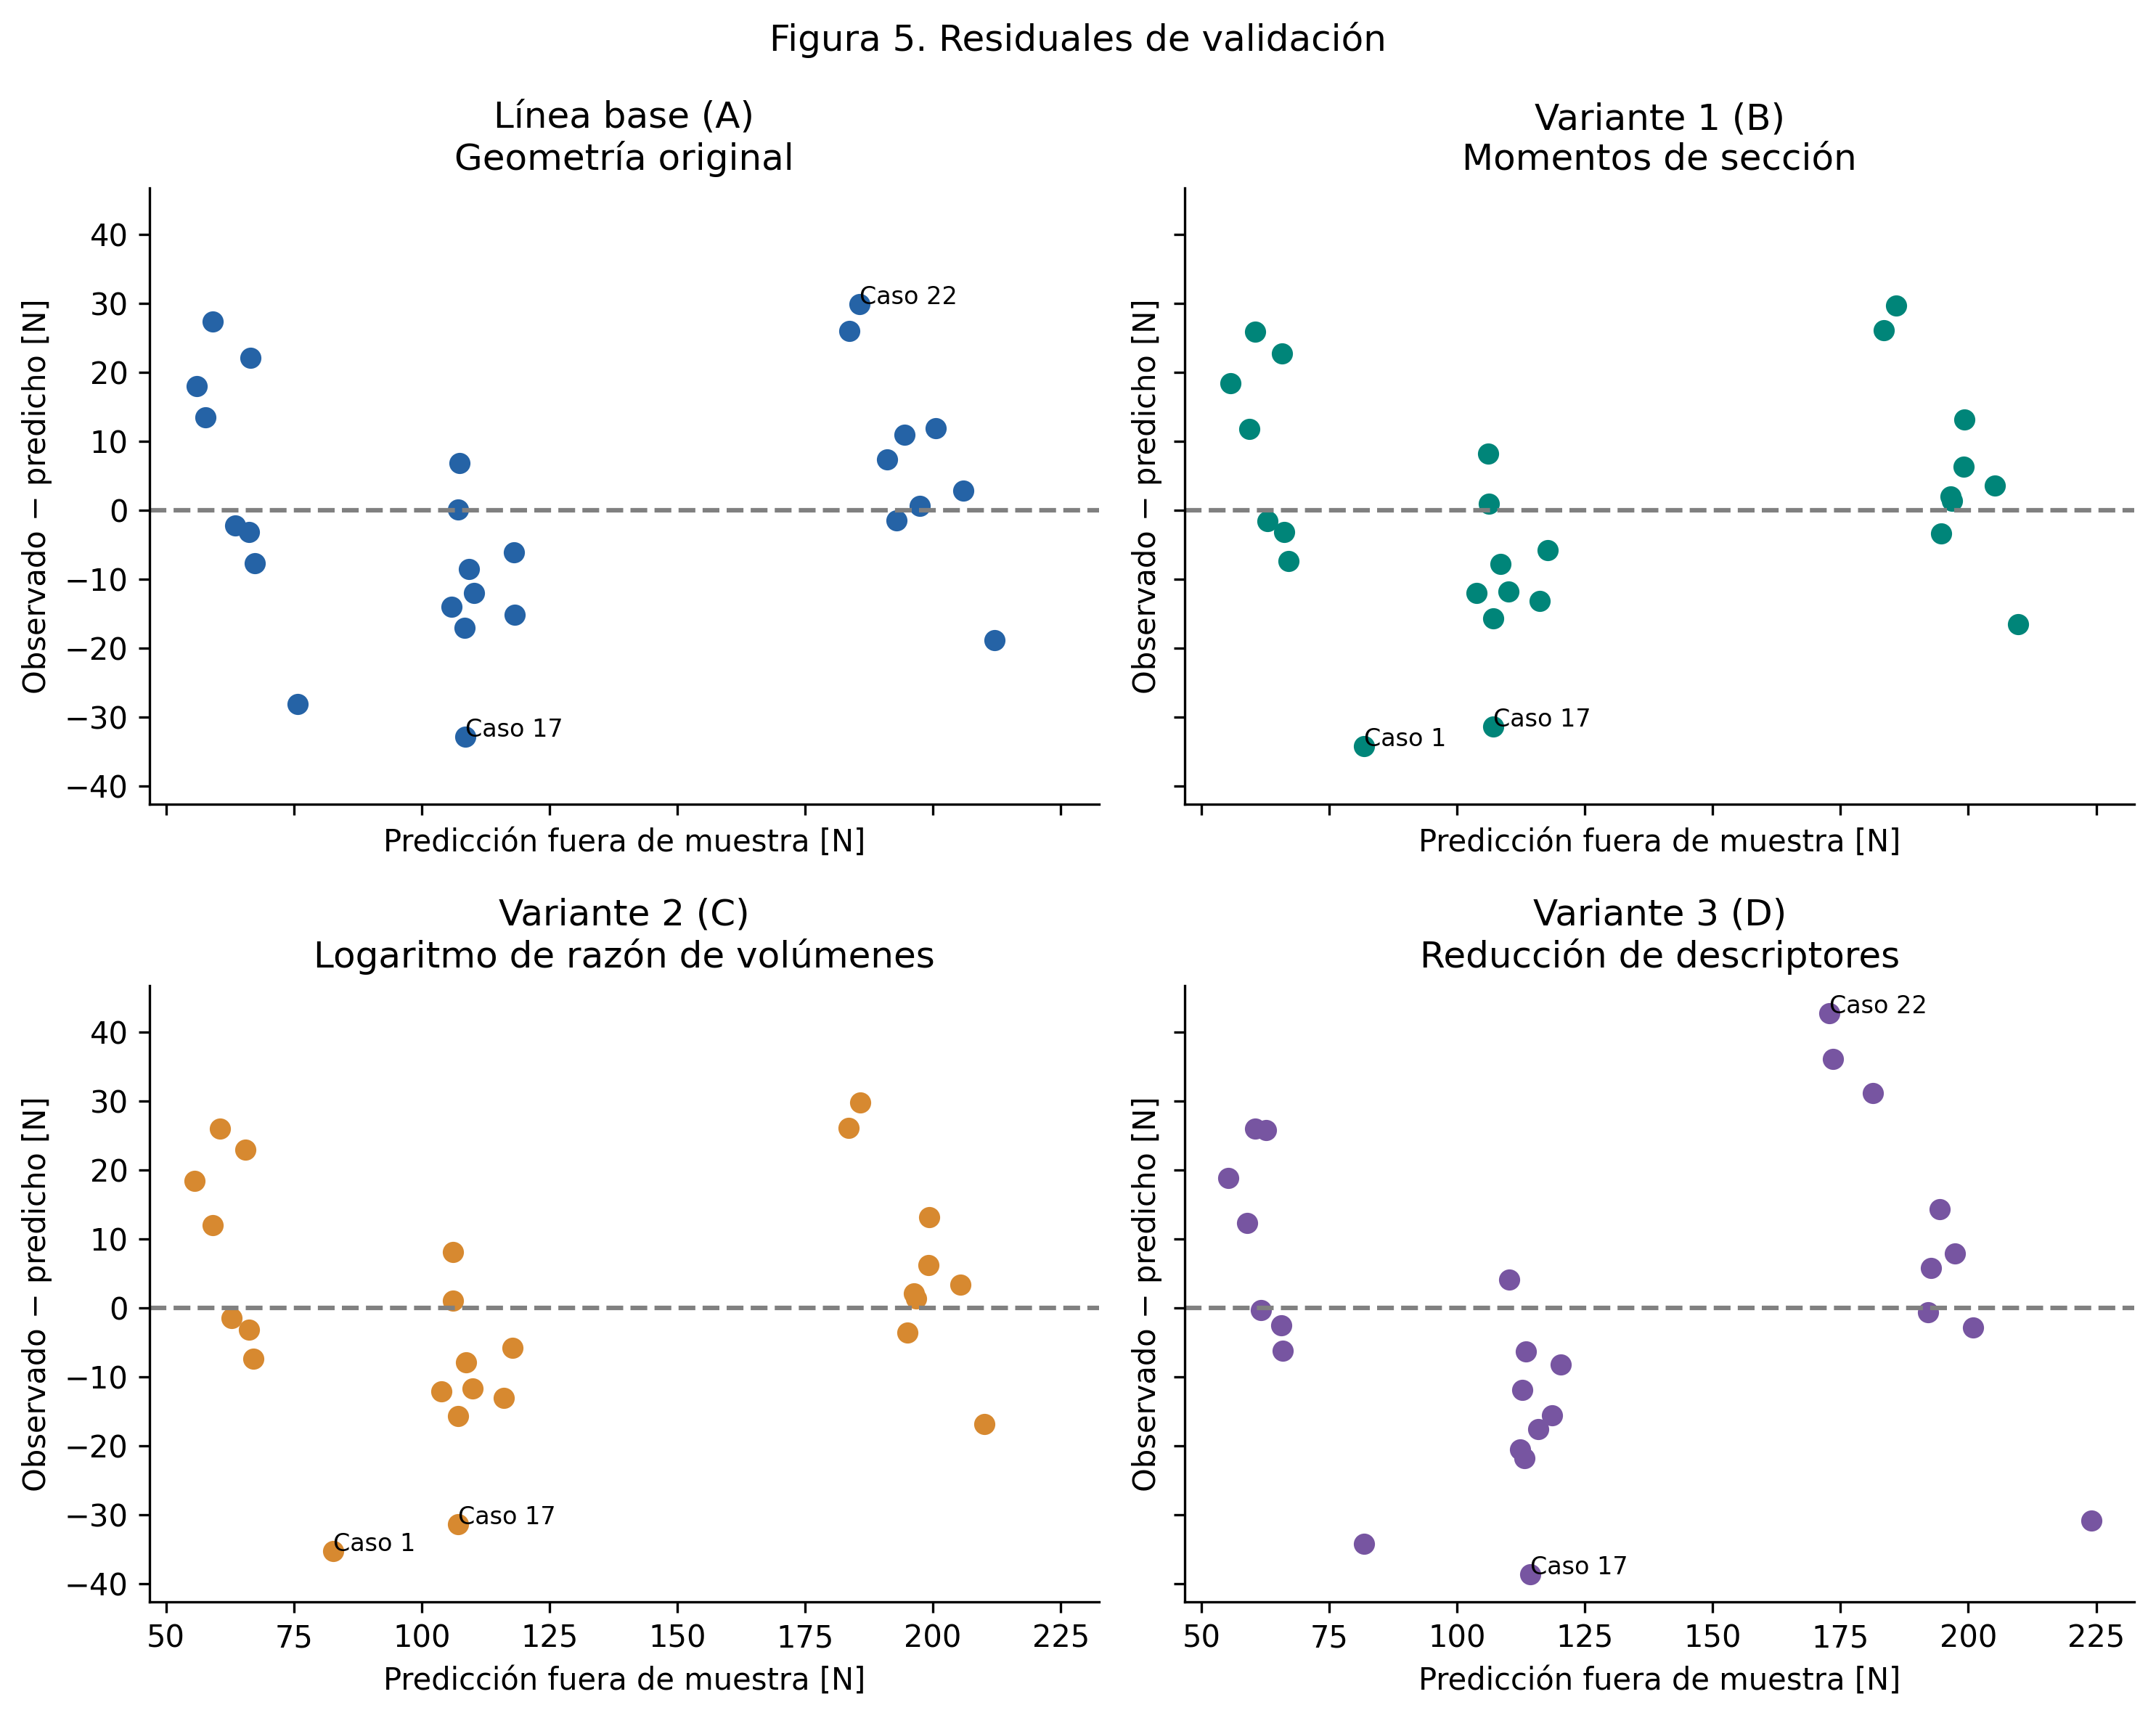

Residual = observado − predicho: positivo indica subestimación. Los casos señalados tienen los mayores errores absolutos; no se eliminan.

In [20]:
mostrar_figura('FE03_residuos')

In [21]:
principal_variante1 = predicciones.query("protocolo == 'configuracion' and experimento == 'B'")
mayores_errores = principal_variante1.nlargest(3, 'error_absoluto_N')
mostrar_tabla(mayores_errores[['Case_n', 'familia', 'observado_N', 'predicho_N', 'residuo_N', 'error_absoluto_N']])
display(Markdown('Los mayores errores señalan dónde revisar la predicción; por sí solos no demuestran un dato erróneo ni justifican eliminarlo.'))

Identificador del caso,Familia (celdas en Y),Carga observada [N],Carga predicha [N],Residual [N],Error absoluto [N]
1,4,47.5500,81.7562,-34.2062,34.2062
17,5,75.7100,107.1136,-31.4036,31.4036
22,6,215.5200,185.8802,29.6398,29.6398


Los mayores errores señalan dónde revisar la predicción; por sí solos no demuestran un dato erróneo ni justifican eliminarlo.

## 4.7 Familias y alcance de generalización

Una familia agrupa estructuras con igual **número de celdas en Y**. La validación principal reserva configuraciones; la prueba adicional reserva una familia completa, cuya arquitectura no aparece en el entrenamiento. Se muestran por separado.

### Figura 6. Error por familia

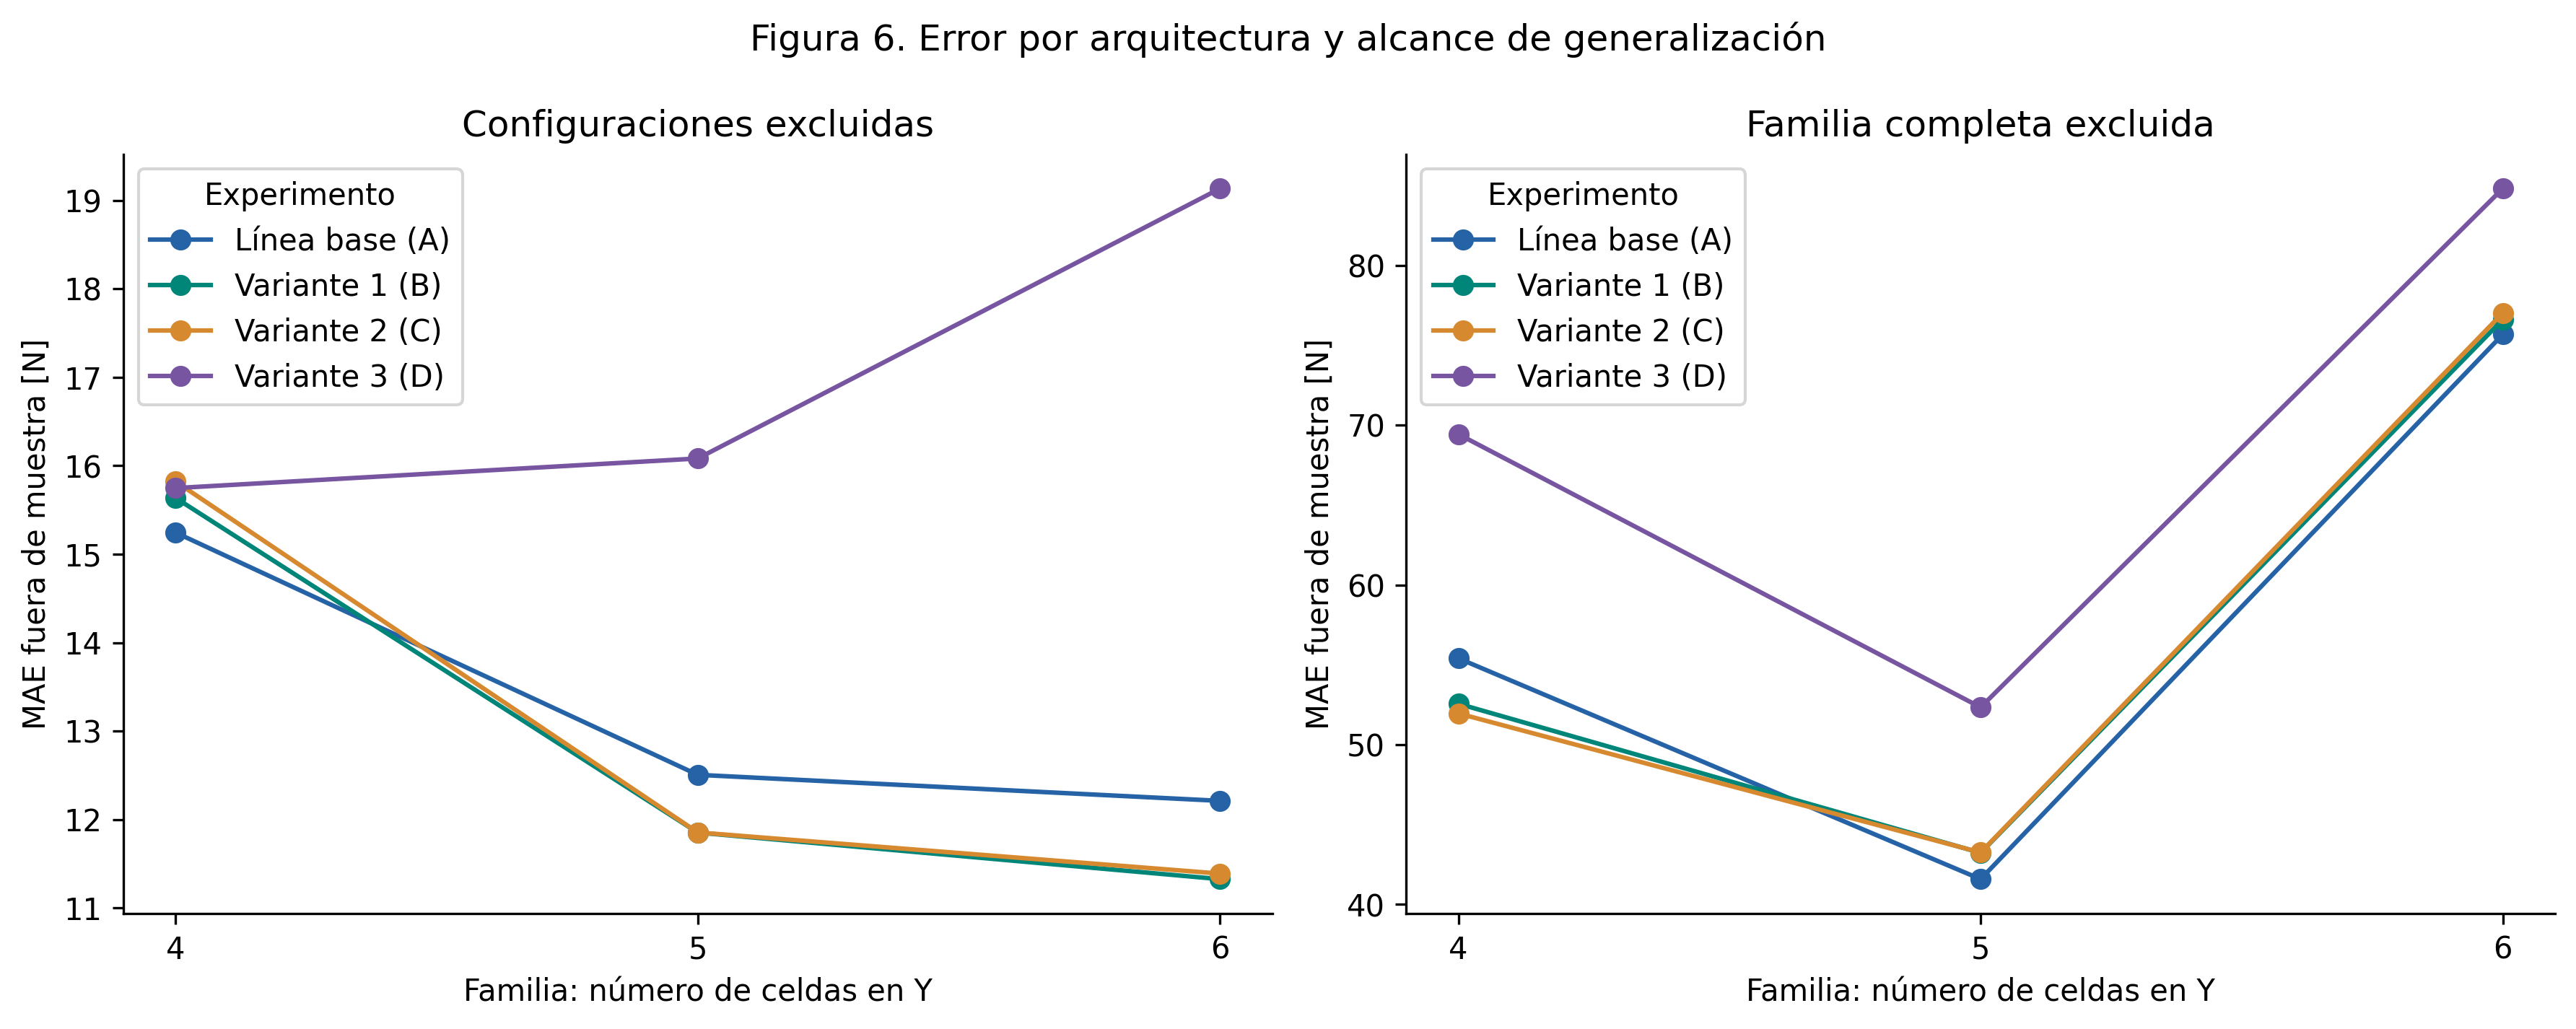

En la validación por configuración, B mejora frente a A en Y=5 y Y=6, pero empeora en Y=4. Excluir una familia completa aumenta mucho el error: generalizar a otra arquitectura sigue sin resolverse.

In [22]:
mostrar_figura('FE04_error_familia')

In [23]:
familias = leer_tabla('errores_familia')
comparacion_familias = familias.query("protocolo == 'configuracion' and experimento in ['A', 'B']").pivot(
    index='familia', columns='experimento', values='MAE_N')
comparacion_familias['ΔMAE variante 1 − base [N]'] = comparacion_familias.B - comparacion_familias.A
comparacion_familias['Cambio con variante 1'] = np.where(
    comparacion_familias['ΔMAE variante 1 − base [N]'] < 0, 'Mejora', 'Empeora')
mostrar_tabla(comparacion_familias.rename(columns={'A': 'MAE base [N]', 'B': 'MAE variante 1 [N]'}).reset_index())
display(Markdown('**Prueba adicional: familia completa excluida.**'))
mostrar_tabla(secundaria.loc[list('ABCD'), metricas + ['tiempo_s', 'predicciones_negativas']].reset_index())
display(Markdown('La variante 1 mejora el error agregado de configuraciones, pero no todas las familias. Las fuerzas negativas de la variante 3 en la prueba adicional son físicamente inadmisibles y se conservan para documentar el fallo de extrapolación.'))

Familia (celdas en Y),MAE base [N],MAE variante 1 [N],ΔMAE variante 1 − base [N],Cambio con variante 1
4,15.2443,15.6359,0.3916,Empeora
5,12.5058,11.8527,-0.6531,Mejora
6,12.2115,11.3265,-0.8850,Mejora


**Prueba adicional: familia completa excluida.**

Experimento,MAE [N],RMSE [N],MedAE [N],R²,Tiempo total [s],Predicciones negativas
Línea base (A),57.6374,60.4281,64.5196,-0.0580,0.0371,0
Variante 1 (B),57.6538,60.4740,61.7609,-0.0596,0.0687,0
Variante 2 (C),57.6190,60.5277,61.6351,-0.0615,0.0784,0
Variante 3 (D),68.8341,71.2923,72.5589,-0.4726,0.0757,4


La variante 1 mejora el error agregado de configuraciones, pero no todas las familias. Las fuerzas negativas de la variante 3 en la prueba adicional son físicamente inadmisibles y se conservan para documentar el fallo de extrapolación.

## 4.8 Aporte de cada intervención y sensibilidad

Se compara variante 1 con la base, variante 2 con variante 1 y variante 3 con variante 2. Un ΔMAE negativo indica mejora. La omisión de errores individuales estudia su contribución al promedio; no elimina esos casos del entrenamiento ni reajusta el modelo.

### Figura 7. Aporte de cada intervención

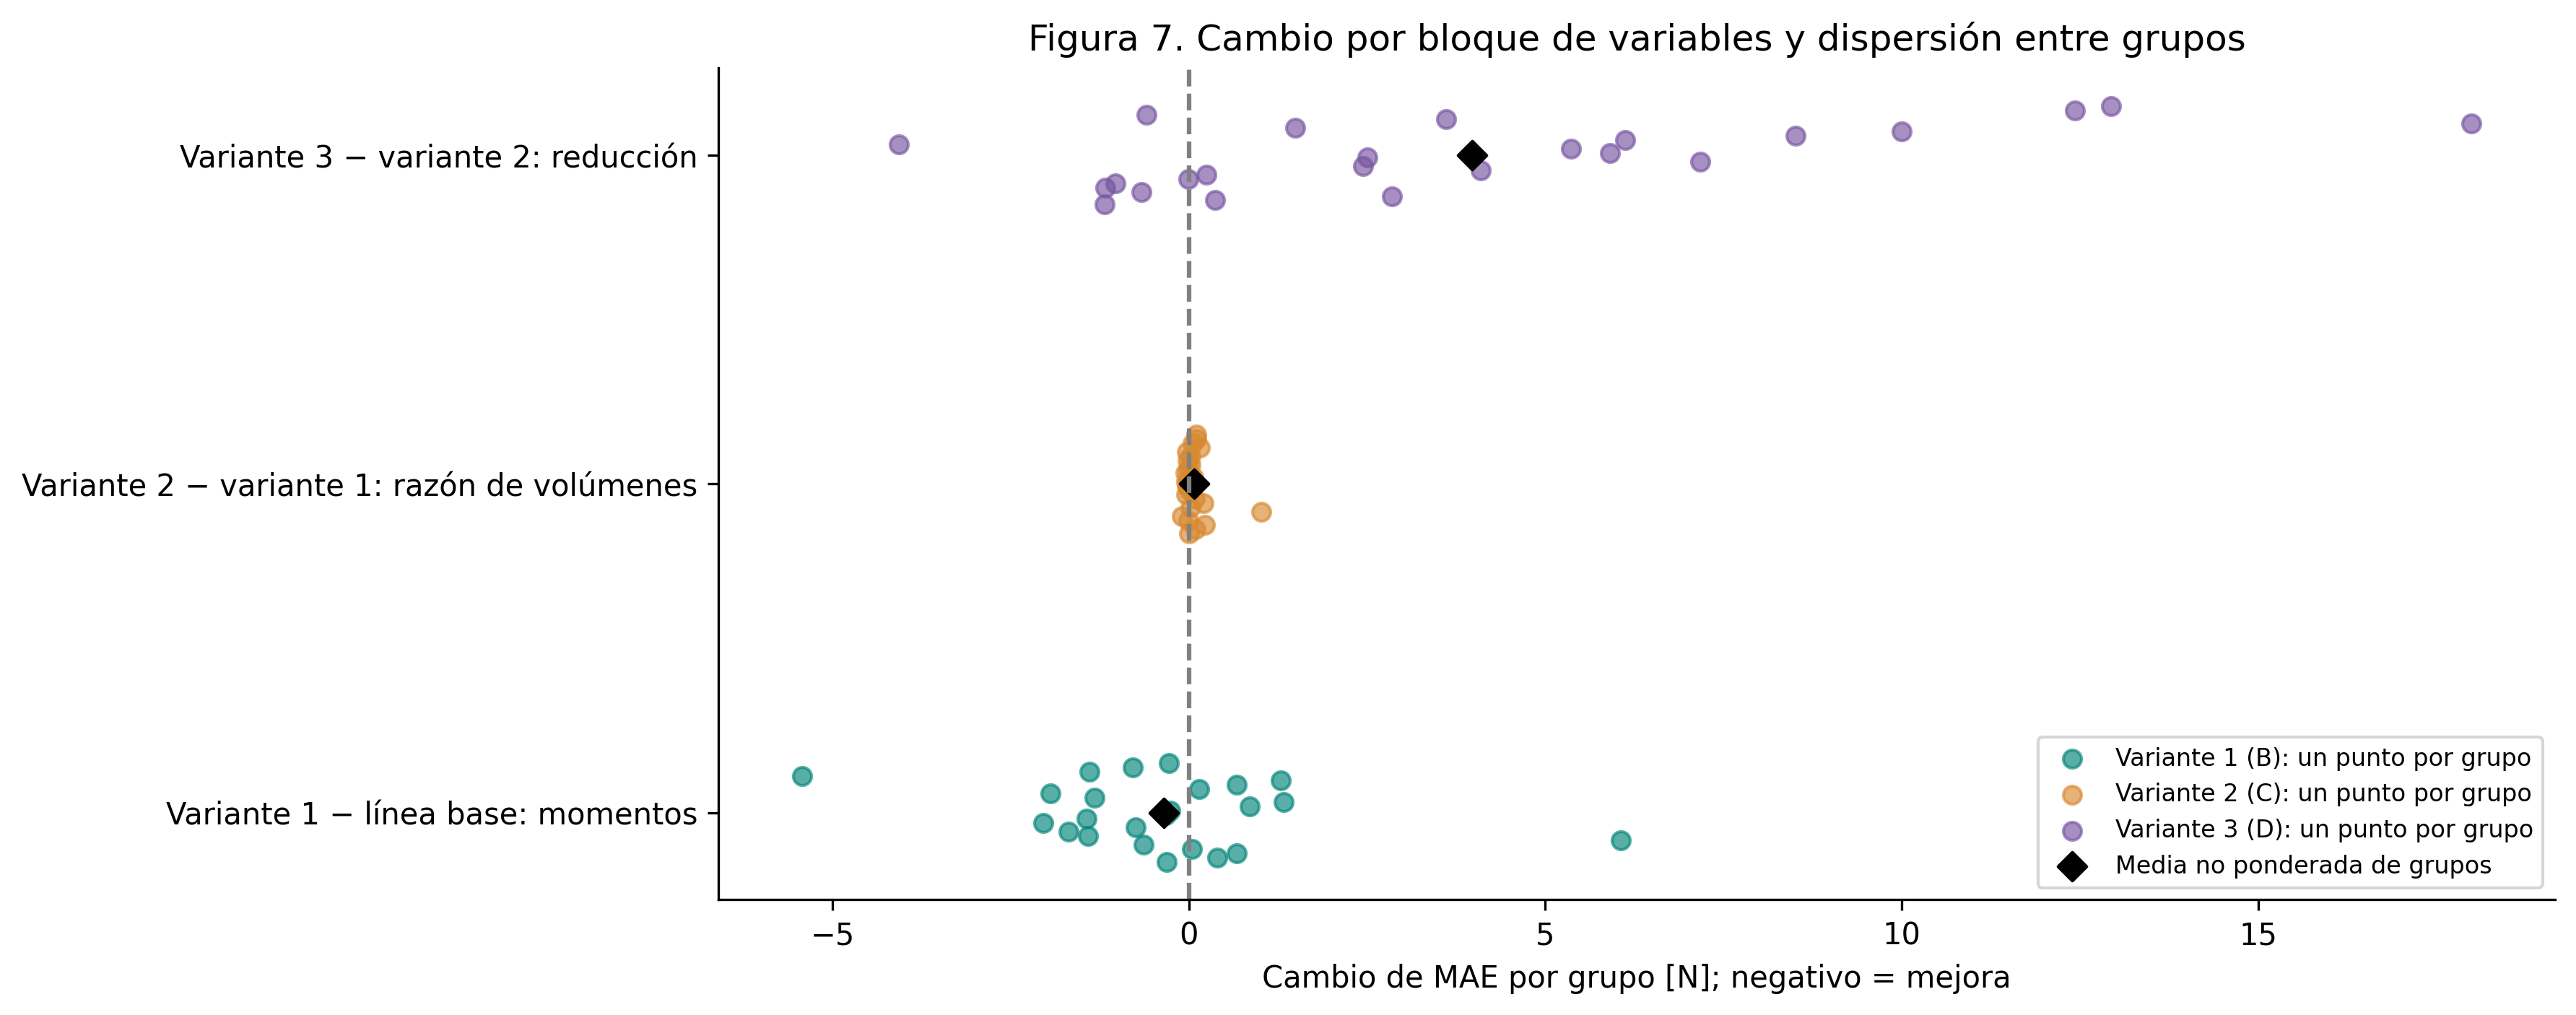

Cada punto es el cambio de MAE de un grupo; negativo indica mejora. El rombo es la media de grupos, no ponderada por casos. No mide importancia causal individual.

In [24]:
mostrar_figura('FE05_ablaciones')

In [25]:
decisiones = leer_tabla('decisiones')
mostrar_tabla(decisiones[['experimento', 'referencia', 'delta_MAE_N', 'delta_RMSE_N',
                         'fraccion_grupos_mejora', 'decision']])
sensibilidad = leer_tabla('sensibilidad_scores')
escenarios = sensibilidad.loc[~sensibilidad.escenario.str.startswith('omitir_score_grupo_')].copy()
escenarios['escenario'] = escenarios.escenario.replace({
    'todos': 'Todos los errores', 'sin_scores_Cook_1_3': 'Omitir errores de casos 1 y 3 (Cook)',
    'sin_scores_revision_pivote': 'Omitir errores de casos con pivote en revisión',
})
mostrar_tabla(escenarios[['experimento', 'escenario', 'delta_MAE_N']])

Experimento,Referencia,ΔMAE [N],ΔRMSE [N],Proporción de grupos que mejoran,Decisión
Variante 1 (B),Línea base (A),-0.4119,-0.1429,0.6250,Mantener en evaluación
Variante 2 (C),Variante 1 (B),0.0792,0.1242,0.3750,Descartar
Variante 3 (D),Variante 2 (C),4.1211,4.8090,0.2917,Descartar


Experimento,Escenario,ΔMAE [N]
Variante 1 (B),Todos los errores,-0.4119
Variante 1 (B),Omitir errores de casos 1 y 3 (Cook),-0.7267
Variante 1 (B),Omitir errores de casos con pivote en revisión,-0.4524
Variante 2 (C),Todos los errores,0.0792
Variante 2 (C),Omitir errores de casos 1 y 3 (Cook),0.0338
Variante 2 (C),Omitir errores de casos con pivote en revisión,0.0755
Variante 3 (D),Todos los errores,4.1211
Variante 3 (D),Omitir errores de casos 1 y 3 (Cook),4.3889
Variante 3 (D),Omitir errores de casos con pivote en revisión,3.2033


In [26]:
omision_grupo = sensibilidad.loc[sensibilidad.escenario.str.startswith('omitir_score_grupo_')]
rango_errores = omision_grupo.groupby(['experimento', 'referencia']).delta_MAE_N.agg(
    minimo='min', maximo='max').reset_index()
rango_errores['Signo al omitir cualquier grupo'] = np.where(
    rango_errores.maximo < 0, 'Siempre mejora',
    np.where(rango_errores.minimo > 0, 'Siempre empeora', 'Cambia de signo'))
mostrar_tabla(rango_errores.rename(columns={'minimo': 'ΔMAE mínimo [N]', 'maximo': 'ΔMAE máximo [N]'}))
display(Markdown('Estos rangos describen contribuciones al error, no intervalos de confianza ni validación independiente.'))

Experimento,Referencia,ΔMAE mínimo [N],ΔMAE máximo [N],Signo al omitir cualquier grupo
Variante 1 (B),Línea base (A),-0.6708,-0.2115,Siempre mejora
Variante 2 (C),Variante 1 (B),0.0417,0.0862,Siempre empeora
Variante 3 (D),Variante 2 (C),3.4288,4.5140,Siempre empeora


Estos rangos describen contribuciones al error, no intervalos de confianza ni validación independiente.

## 4.9 Interpretación de resultados

In [27]:
regla = configuracion['decision_rule']
resultado_variante1 = decisiones.set_index('experimento').loc['B']
criterios = pd.DataFrame([
    ['Reducción de MAE (%)', f">= {regla['adopt_min_mae_reduction_percent']:g}",
     resultado_variante1.reduccion_MAE_pct,
     resultado_variante1.reduccion_MAE_pct >= regla['adopt_min_mae_reduction_percent']],
    ['Grupos con menor error (%)', f">= {100 * regla['adopt_min_group_win_fraction']:g}",
     100 * resultado_variante1.fraccion_grupos_mejora,
     resultado_variante1.fraccion_grupos_mejora >= regla['adopt_min_group_win_fraction']],
    ['ΔRMSE frente a la base [N]', '<= 0', resultado_variante1.delta_RMSE_N, resultado_variante1.delta_RMSE_N <= 0],
    ['ΔMAE agregado al excluir familias [N]', '<= 0', resultado_variante1.delta_MAE_familia_N,
     resultado_variante1.delta_MAE_familia_N <= 0],
], columns=['Criterio para adoptar variante 1', 'Regla', 'Resultado', 'Cumple'])
criterios['Cumple'] = criterios.Cumple.map({True: 'Sí', False: 'No'})
mostrar_tabla(criterios)

diferencia = principal.loc['B', 'MAE_N'] - principal.loc['A', 'MAE_N']
display(Markdown(
    f'**Momentos de sección:** la variante 1 obtiene MAE {principal.loc["B", "MAE_N"]:.2f} N '
    f'(Δ frente a la base: {diferencia:.3f} N). La mejora es pequeña y desigual por familia; '
    'cumple solo parte de las reglas y se mantiene en evaluación.'))
display(Markdown(
    '**Razón y reducción:** añadir la razón logarítmica no mejora la variante 1. '
    'Retirar el bloque geométrico empeora la variante 2. El cambio de representación '
    'también modifica la penalización efectiva de Ridge.'))
display(Markdown(
    f'**Generalización:** al excluir familias completas, el MAE de la variante 1 es {secundaria.loc["B", "MAE_N"]:.2f} N. '
    'El EDA ya examinó el mismo conjunto; esta comparación es exploratoria. '
    'Corresponde confirmar la base y la variante 1 con geometrías conciliadas y ensayos independientes.'))

Criterio para adoptar variante 1,Regla,Resultado,Cumple
Reducción de MAE (%),>= 5,3.1097,No
Grupos con menor error (%),>= 60,62.5000,Sí
ΔRMSE frente a la base [N],<= 0,-0.1429,Sí
ΔMAE agregado al excluir familias [N],<= 0,0.0164,No


**Momentos de sección:** la variante 1 obtiene MAE 12.83 N (Δ frente a la base: -0.412 N). La mejora es pequeña y desigual por familia; cumple solo parte de las reglas y se mantiene en evaluación.

**Razón y reducción:** añadir la razón logarítmica no mejora la variante 1. Retirar el bloque geométrico empeora la variante 2. El cambio de representación también modifica la penalización efectiva de Ridge.

**Generalización:** al excluir familias completas, el MAE de la variante 1 es 57.65 N. El EDA ya examinó el mismo conjunto; esta comparación es exploratoria. Corresponde confirmar la base y la variante 1 con geometrías conciliadas y ensayos independientes.

## 4.10 Entregables y control de integridad

La entrega y su README están en la rama **feature-engineering**, separada del EDA. El notebook conserva el mismo enlace para compartir sus actualizaciones.

In [28]:
from src.ingesta import sha256_file
manifiesto = json.loads((SALIDA / 'manifest.json').read_text(encoding='utf-8'))
assert all(sha256_file(RAIZ / p) == huella for p, huella in manifiesto['inputs_sha256'].items())
assert all(sha256_file(SALIDA / p) == huella for p, huella in manifiesto['artifacts_sha256'].items())
archivos = {
    'Tratamiento de variables y justificacion': 'reports/feature_engineering/tables/tratamiento_decisiones.csv',
    'Valores antes y despues de estandarizar': 'reports/feature_engineering/tables/tratamiento_escalamiento.csv',
    'Experimentos ejecutados e intervenciones': 'reports/feature_engineering/ejecucion.log',
    'Métricas y tiempos comparables': 'reports/feature_engineering/tables/comparacion_experimentos.csv',
    'Gráfico de residuales para regresión': 'reports/feature_engineering/figures/FE03_residuos.png',
    'Variables añadidas y retiradas': 'reports/feature_engineering/tables/diccionario_features.csv',
    'Equivalencia de nombres en español': 'reports/feature_engineering/tables/nombres_variables.csv',
    'Divisiones por grupos': 'reports/feature_engineering/particiones.json',
    'Preprocesamiento por entrenamiento': 'reports/feature_engineering/auditoria_transformaciones.json',
    'README de la entrega': 'README.md',
}
assert all((RAIZ / ruta).is_file() for ruta in archivos.values())
display(Markdown('**Integridad comprobada.**\n\n' + '\n\n'.join(
    f'- [{nombre}](../{ruta})' for nombre, ruta in archivos.items())))

**Integridad comprobada.**

- [Tratamiento de variables y justificacion](../reports/feature_engineering/tables/tratamiento_decisiones.csv)

- [Valores antes y despues de estandarizar](../reports/feature_engineering/tables/tratamiento_escalamiento.csv)

- [Experimentos ejecutados e intervenciones](../reports/feature_engineering/ejecucion.log)

- [Métricas y tiempos comparables](../reports/feature_engineering/tables/comparacion_experimentos.csv)

- [Gráfico de residuales para regresión](../reports/feature_engineering/figures/FE03_residuos.png)

- [Variables añadidas y retiradas](../reports/feature_engineering/tables/diccionario_features.csv)

- [Equivalencia de nombres en español](../reports/feature_engineering/tables/nombres_variables.csv)

- [Divisiones por grupos](../reports/feature_engineering/particiones.json)

- [Preprocesamiento por entrenamiento](../reports/feature_engineering/auditoria_transformaciones.json)

- [README de la entrega](../README.md)